# Microbiome-Based Disease Prediction at Genus Level: DeepPhylo vs. Random Forest

This notebook benchmarks a phylogeny-aware deep-learning model (**DeepPhylo**) against a
standard **Random Forest** baseline for predicting disease status from 16S microbiome
abundance profiles. It is organised into two independent analyses:

1. **Oral disease classification (Leave-One-Study-Out).** Using pooled oral samples from many
   public studies, we predict each disease vs. healthy controls (HC), always holding out one
   *entire study* for testing. This measures how well a model generalises **across studies**
   (different labs, protocols, and batch effects).

2. **Paired oral–gut projects (within-study 5-fold CV).** Using studies that sampled both oral
   and gut sites from the same cohorts, we predict disease vs. HC separately for each body site
   with stratified cross-validation, so we can compare how predictive each site is.

For both analyses, DeepPhylo and Random Forest are run on **identical data splits** and their
per-split AUC is compared.

> **Environment note.** The code expects a local `DeepPhylo` package, the microbiome `.biom`
> tables and metadata files, and a precomputed phylogenetic embedding on disk. The paths are
> specific to the original machine and would need to be adjusted to re-run elsewhere.

# Methods

## Microbiome datasets and study cohorts

Disease status was predicted from 16S rRNA gene amplicon microbiome profiles
assembled from multiple publicly available studies. Two complementary
collections were analysed. The first was a pooled **oral** collection, in which
samples from many independent studies were aggregated to enable cross-study
evaluation of disease-versus-healthy-control (HC) classification. The second was
a set of **paired oral–gut** projects, in which the oral and gut microbiota were
sampled from the same cohorts, allowing a within-study comparison of the
predictive value of each body site. For each collection, feature tables were
stored as BIOM-format genus count matrices with
accompanying sample metadata (body site, disease status, and study/BioProject
identifier).

## Quality control and feature filtering

Identical quality-control (QC) criteria were applied to both collections. First,
the feature table was restricted to samples present in the metadata, and empty
features and samples were removed. Rare genera, defined as those detected in 50 or
fewer samples, were discarded to reduce noise and dimensionality. Samples with a
sequencing depth below 1,000 total reads were removed as unreliable. After each
filtering step the table was re-checked for empty rows and columns, and the
metadata were re-synchronised to the surviving samples. Samples with a missing
disease label or a non-specific "Other" label were excluded so that every
retained sample carried a well-defined disease or HC status. Finally, per-sample
relative abundances were obtained by total-sum normalisation of the filtered
count table, and the resulting abundance matrix was aligned to a fixed,
phylogenetically ordered set of genera (see below).

## Phylogenetic feature representation

DeepPhylo exploits the evolutionary relationships among taxa. A cophenetic
(patristic) distance matrix encoding the pairwise phylogenetic tree distances
between genera was used to derive a phylogeny-informed taxa embedding. genera were
arranged in a fixed phylogenetic order so that evolutionarily related taxa occupy
neighbouring positions, allowing the abundance profile of each sample to be
treated as a one-dimensional signal. Both the ordered genus list and the
precomputed phylogenetic embedding were shared across all experiments to ensure
that every model and data split used an identical feature representation.

## DeepPhylo model and training

The phylogeny-aware classifier (DeepPhylo) applies one-dimensional convolutional
filters across the phylogenetically ordered genera, so that each filter integrates
information from neighbouring (evolutionarily related) taxa. The network used a
hidden dimension of 80, a convolutional kernel of size 3, and a pooling kernel of
size 7, with rectified linear unit (ReLU) activations, and produced a single
sigmoid output representing the predicted disease probability.

Models were trained by minimising the binary cross-entropy loss using the AdamW
optimiser with a learning rate of 1×10⁻³ and a batch size of 32, for up to 100
epochs. Within every training set, 15% of the samples were held out as an
internal validation set, and early stopping was applied with a patience of 10
epochs; the weights from the epoch with the lowest validation loss were retained
for prediction. When class sizes permitted, the internal train/validation split
was stratified by label. A fixed random seed was used throughout to promote
reproducibility, and all models were trained on GPU when available.

## Random Forest baseline

As a baseline, a Random Forest classifier was trained on the same relative
abundance features. It comprised 100 trees with balanced class weights to
mitigate class imbalance, and used a fixed random seed. Critically, the Random
Forest and DeepPhylo models were trained and evaluated on **identical data
splits** in every experiment, so that their per-split performance is directly
comparable. Predicted disease probabilities were taken from the positive-class
output of the fitted forest.

## Evaluation design 1: cross-study generalisation (leave-one-study-out)

Cross-study generalisation was assessed on the oral collection using a
leave-one-study-out (LOSO) scheme, applied separately to each oral site
(saliva, tooth, tongue, and oral mucosa). Within each site, studies and diseases
were selected according to three criteria: (i) a study was retained only if it
contained both HC samples and at least one disease group; (ii) a study was
required to include more than 10 HC samples so that the control group was not
negligibly small; and (iii) a disease was analysed only if it was present in at
least two studies, which is the minimum required for LOSO (one study to train on
and one to hold out).

For each qualifying disease, every study was in turn held out entirely as the
test set while the model was trained on the remaining studies, framing the task
as the target disease versus HC. Because the held-out study contributes its own
laboratory- and protocol-specific batch effects, this design provides a strict
test of generalisation to unseen studies. Splits in which either the training or
test partition lacked both classes—for which the area under the receiver
operating characteristic curve (AUC) is undefined—were skipped. The test AUC was
recorded for every evaluable study, and results were aggregated per disease and
per site.

## Evaluation design 2: within-study cross-validation (paired oral–gut)

The paired oral–gut collection was used to compare the predictive value of the
oral and gut microbiomes within the same cohorts. Samples were grouped by
(project × body site × disease status), and only groups containing more than 10
samples were retained. A project was evaluated only if it contained all four
expected groups—both body sites, each with HC and disease samples—so that the
oral-versus-gut comparison was always made on the same cohort.

For each qualifying project, the task was defined as disease (any non-HC status)
versus HC and was evaluated **separately** for the gut and oral samples using
stratified five-fold cross-validation. Within each training fold, an internal
validation split (15%) was used for early stopping of DeepPhylo, exactly as in
the LOSO analysis. Projects or sites whose smaller class contained fewer samples
than the number of folds were skipped, as were individual folds whose test
partition did not contain both classes. Per-fold test AUC was recorded, and a
per-(project × site) summary (mean and standard deviation across folds) was
computed.

## Performance evaluation and model comparison

Classification performance was quantified throughout by the AUC, computed from
the predicted disease probabilities on each held-out partition. Because DeepPhylo
and Random Forest were evaluated on identical splits within both designs, the two
models could be compared directly at the level of the individual test study
(LOSO) or the individual fold, study, and body site (five-fold cross-validation),
with an AUC of 0.5 denoting chance-level performance. For the paired oral–gut
analysis, each project was additionally annotated with its associated disease
(the single non-HC status present in the project) to enable disease-level
comparison. Results were visualised as per-site and per-disease comparisons of
DeepPhylo versus Random Forest AUC, with paired points connected across models to
highlight per-study differences.

In [2]:
import sys

import matplotlib as mpl
import os
import math
import biom
import numpy as np
import pandas as pd
from sklearn.model_selection import KFold
from sklearn.metrics import r2_score
from sklearn.model_selection import StratifiedKFold, train_test_split

In [3]:
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
import seaborn as sns

In [4]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

In [6]:
from itertools import product

In [7]:
import random
from math import comb
from itertools import combinations

In [8]:
# ---------------------------------------------------------------------------
# Genus-level aggregation helper
# ---------------------------------------------------------------------------
# Taxonomy file for all OTU / feature IDs in the global oral collection.
TAXONOMY_PATH = "/beegfs/huangxiaochang/global_oral/taxonomy.tsv"


def _parse_genus(taxon_str):
    """Extract the genus label (g__...) from a semicolon-separated taxonomy string."""
    if pd.isna(taxon_str):
        return None
    parts = [p.strip() for p in str(taxon_str).split(";")]
    for p in parts:
        if p.startswith("g__"):
            return p
    return None


# Load once and build a global Feature ID -> genus map.
_taxonomy = pd.read_csv(TAXONOMY_PATH, sep="\t")
_taxonomy["genus"] = _taxonomy["Taxon"].apply(_parse_genus)
_taxonomy = _taxonomy.dropna(subset=["genus"])
FID_TO_GENUS = dict(zip(_taxonomy["Feature ID"].astype(str), _taxonomy["genus"]))
print(f"[genus] loaded taxonomy for {len(FID_TO_GENUS)} features")


def aggregate_to_genus(table):
    """Collapse a BIOM feature table to genus level.

    Observations without a genus annotation are dropped; remaining observations
    are summed by their genus label.
    """
    obs_ids = table.ids(axis="observation")
    keep = [fid for fid in obs_ids if fid in FID_TO_GENUS]
    if not keep:
        raise ValueError("No observation IDs in the table could be mapped to genus.")
    table = table.filter(keep, axis="observation", inplace=False)

    def _genus_mapper(id_, md):
        return FID_TO_GENUS[id_]

    return table.collapse(_genus_mapper, axis="observation")

[genus] loaded taxonomy for 337506 features


# Part 1 — Oral disease classification (Leave-One-Study-Out)

## Load the oral dataset and apply quality control

We load the oral `.biom` genus table and its metadata, then apply standard microbiome QC:

- keep only samples that appear in the metadata;
- drop **rare genera** (present in ≤ 50 samples) to cut noise and dimensionality;
- drop **low-depth samples** (< 1,000 total reads), which are unreliable;
- remove any now-empty rows/columns and re-sync the metadata to the surviving samples.

In [91]:
table = biom.load_table("../../data/metadata-and-biom-v2-qc/biom_oral_qc_dedup.biom")
table = aggregate_to_genus(table)
metadata = pd.read_csv("../../data/metadata-and-biom-v2-qc/metadata_oral_qc_dedup.tsv", sep="\t", low_memory=False)
sid = metadata.sample_id.values
table.filter(sid, axis="sample")
table.remove_empty()
# fid = table.ids(axis="observation")
# prevalence = table.nonzero_counts(axis="observation")
# table = table.filter(fid[prevalence > 50], axis='observation', inplace=False)
# table.remove_empty()
sid_reads = table.sum(axis="sample")
sid = table.ids(axis="sample")
table = table.filter(sid[sid_reads > 1000], axis='sample', inplace=False)
table.remove_empty()

sid = table.ids(axis="sample")
metadata = metadata.loc[[i in sid for i in metadata.sample_id.values]]

In [64]:
metadata.columns

Index(['bioproject_id', 'sample_id', 'subject_id', 'chim_perc', 'asv_count',
       'total_reads', 'sample_cr_mapping_rate', 'study_cr_mapping_rate',
       'Observed', 'Shannon', 'Simpson', 'InvSimpson', 'Chao1', 'age',
       'age_info', 'bmi', 'sex', 'platform', 'sequencing_region',
       'pcr_primers', 'country', 'site', 'site_group', 'disease_study',
       'status', 'title', 'public_time', 'matched_samples', 'is_time_series',
       'age_cleaned', 'bmi_cleaned', 'age_cleaned_group', 'age_info_cleaned',
       'bmi_cleaned_group', 'sex_cleaned', 'platform_cleaned',
       'sequencing_region_cleaned', 'country_cleaned', 'continent_group',
       'site_cleaned', 'site_group_cleaned', 'disease_study_cleaned',
       'status_cleaned', 'chim_gt_25', 'study_chim_gt25_high',
       'sample_cr_mapping_low', 'study_cr_mapping_low'],
      dtype='object')

In [65]:
metadata.status_cleaned.unique()

array(['Dental Caries', 'OSCC', 'HC', 'Gastroesophageal Reflux Disease',
       'Obstructive Sleep Apnea', 'Hypertension', nan, 'Other', 'HIV',
       'IBD', 'Diabetes', 'Clostridium Difficile Infection', 'ICU',
       'Obesity', 'Asthma', 'Periodontal Disease', 'Atopic Dermatitis',
       'Chagas Disease', 'Head and Neck Cancer',
       'Oral Submucous Fibrosis', 'Oral Mucositis',
       'Oral Verrucous Hyperplasia', 'Preterm', 'Breast Cancer',
       'COVID-19', 'Prostate Cancer', 'Colorectal Cancer',
       'Oral Lichen Planus', 'Celiac Disease', 'Acute Myeloid Leukemia',
       'Lung Cancer', "Sjögren's Syndrome", 'Pancreatic Cancer',
       'Aphthous', 'Helicobacter pylori Infection',
       'Autoimmune Hepatitis', 'RA', 'Non-Carious Cervical Lesions',
       'Alcohol Use Disorder', 'Esophageal Cancer',
       'Hand, Foot and Mouth Disease', "Parkinson's Disease",
       'COVID-19 discharge', '1-year COVID-19 convalescent',
       'Nonmalignant Breast Disease', 'Thyroid Cancer', '

In [93]:
table.shape

(4316, 25803)

In [98]:
# ---------------- Parameters ----------------
META_PATH = "../../data/metadata-and-biom-v2-qc/metadata_oral_qc_dedup.tsv"
MIN_CASE_TOTAL   = 30         # minimum pooled case samples across matched BPs
MIN_HC_TOTAL     = 30         # minimum pooled HC samples across matched BPs
MIN_MATCHED_BP   = 2          # minimum number of matched BPs per site
ABUND_THRESH     = 0.01       # keep a genus if mean rel. abundance >= 1% in any cohort
COHORT_COL       = "bioproject_id"
RENORM_AFTER_FILTER = True    # renormalize each sample to 1 after genus filtering

oral_sites = ['saliva', 'tooth', 'tongue', 'oral mucosa']
run_site, run_disease, run_test_study = [], [], []


def genus_keep_by_cohort_abundance(table_rel, meta_sub, thresh=ABUND_THRESH,
                                   cohort_col=COHORT_COL):
    """Keep genera whose mean relative abundance is >= thresh in at least one cohort."""
    fid = np.asarray(table_rel.ids(axis="observation"))
    sid = np.asarray(table_rel.ids(axis="sample"))
    mat = pd.DataFrame(table_rel.matrix_data.toarray(), index=fid, columns=sid)  # genus x sample
    cohort = meta_sub.set_index("sample_id").loc[sid, cohort_col].astype(str).values
    mean_by_cohort = mat.T.groupby(cohort).mean().T
    keep = mean_by_cohort.max(axis=1) >= thresh
    return fid[keep.values], mean_by_cohort


def get_matched_bp(metadata_site, disease):
    """Return matched BPs (both HC and disease present, pooled sizes large enough),
    or [] if the site does not qualify for this disease."""
    counts = (metadata_site.groupby(["bioproject_id", "status_cleaned"])["sample_id"]
                            .count().reset_index(name="n"))
    sub = counts[counts.status_cleaned.isin(["HC", disease])]
    matched_bp = (sub.groupby("bioproject_id")["status_cleaned"].nunique()
                     .pipe(lambda x: x[x == 2]).index.tolist())
    if len(matched_bp) < MIN_MATCHED_BP:
        return []

    sub = sub[sub.bioproject_id.isin(matched_bp)]
    n_case = int(sub.loc[sub.status_cleaned == disease, "n"].sum())
    n_hc   = int(sub.loc[sub.status_cleaned == "HC", "n"].sum())
    if n_case < MIN_CASE_TOTAL or n_hc < MIN_HC_TOTAL:
        return []
    return matched_bp


# ---------------- 0) Load & pre-clean metadata once ----------------
sid_all = table.ids(axis="sample")
metadata_all = pd.read_csv(META_PATH, sep="\t", low_memory=False)
metadata_all = metadata_all.loc[metadata_all.status_cleaned.notna()]
metadata_all = metadata_all.loc[metadata_all.status_cleaned != "Other"]
metadata_all = metadata_all.loc[metadata_all.sample_id.isin(set(sid_all))]
metadata_all = metadata_all.loc[metadata_all.site_cleaned.isin(oral_sites)]

all_diseases = sorted(metadata_all.loc[metadata_all.status_cleaned != "HC",
                                       "status_cleaned"].unique())

# ---------------- 1) Filter by disease first: how many sites does it qualify in ----------------
for disease in all_diseases:
    print(f"\n########## DISEASE: {disease} ##########")

    site_matched_bp = {}   # site -> matched_bp list
    for site in oral_sites:
        metadata_site = metadata_all.loc[metadata_all.site_cleaned == site]
        if metadata_site.empty:
            continue
        matched_bp = get_matched_bp(metadata_site, disease)
        if matched_bp:
            site_matched_bp[site] = matched_bp

    print(f"  Qualifies in {len(site_matched_bp)} site(s): {list(site_matched_bp.keys())}")

    # ---------------- 2) Leave-one-study-out per qualifying site ----------------
    for site, matched_bp in site_matched_bp.items():
        print(f"\n=== Processing: {disease} | {site} ===")

        metadata_site = metadata_all.loc[metadata_all.site_cleaned == site]
        meta_pick = metadata_site.loc[
            metadata_site.bioproject_id.isin(matched_bp)
            & metadata_site.status_cleaned.isin(["HC", disease])
        ].copy()
        sid = meta_pick.sample_id.values
        table_pick = table.filter(sid, axis="sample", inplace=False)

        # Convert to relative abundance, then filter genera
        table_pick.norm(axis="sample", inplace=True)
        keep_fid, mean_by_cohort = genus_keep_by_cohort_abundance(table_pick, meta_pick)
        print(f"  genus: {table_pick.shape[0]} -> {len(keep_fid)} "
              f"(mean relative abundance >= {ABUND_THRESH:.0%} in at least one cohort)")
        if len(keep_fid) == 0:
            print("  No genus passed the abundance filter, skipping...")
            continue

        table_pick = table_pick.filter(keep_fid, axis="observation", inplace=False)
        if RENORM_AFTER_FILTER:
            table_pick.norm(axis="sample", inplace=True)
        if table_pick.shape[1] == 0:
            continue

        # ---- Leave-one-study-out ----
        print(f"  {len(matched_bp)} bioprojects with {len(meta_pick)} samples")
        for j in matched_bp:
            run_disease.append(disease.replace(' ', '_'))
            run_site.append(site.replace(' ', '_'))
            run_test_study.append(j)

            train_sid = meta_pick.loc[meta_pick.bioproject_id != j, "sample_id"].values
            test_sid  = meta_pick.loc[meta_pick.bioproject_id == j, "sample_id"].values
            train_biom = table_pick.filter(train_sid, axis="sample", inplace=False)
            test_biom  = table_pick.filter(test_sid,  axis="sample", inplace=False)
            print(f"    [test={j}] train: {train_biom.shape}, test: {test_biom.shape}")

            tag = f"{site.replace(' ', '_')}_{disease.replace(' ', '_')}_{j}"
            with biom.util.biom_open(f"data/lso_genus_train_{tag}.biom", 'w') as f:
                train_biom.to_hdf5(f, 'example')
            with biom.util.biom_open(f"data/lso_genus_test_{tag}.biom", 'w') as f:
                test_biom.to_hdf5(f, 'example')


########## DISEASE: 1-year COVID-19 convalescent ##########
  Qualifies in 0 site(s): []

########## DISEASE: Acute Myeloid Leukemia ##########
  Qualifies in 0 site(s): []

########## DISEASE: Alcohol Use Disorder ##########
  Qualifies in 0 site(s): []

########## DISEASE: Alzheimer's Disease ##########
  Qualifies in 0 site(s): []

########## DISEASE: Aphthous ##########
  Qualifies in 0 site(s): []

########## DISEASE: Asthma ##########
  Qualifies in 0 site(s): []

########## DISEASE: Atopic Dermatitis ##########
  Qualifies in 0 site(s): []

########## DISEASE: Autoimmune Hepatitis ##########
  Qualifies in 0 site(s): []

########## DISEASE: Axial Spondyloarthritis ##########
  Qualifies in 0 site(s): []

########## DISEASE: Breast Cancer ##########
  Qualifies in 1 site(s): ['saliva']

=== Processing: Breast Cancer | saliva ===
  genus: 4316 -> 37 (mean relative abundance >= 1% in at least one cohort)
  2 bioprojects with 748 samples
    [test=PRJEB70783] train: (37, 252), test

In [99]:
run_info = pd.DataFrame({"site": run_site, "disease": run_disease, "study": run_test_study})

In [100]:
run_info.head()

,site,disease,study
0,saliva,Breast_Cancer,PRJEB70783
1,saliva,Breast_Cancer,PRJNA767189
2,saliva,Colorectal_Cancer,PRJEB70783
3,saliva,Colorectal_Cancer,PRJNA801882
4,saliva,Dental_Caries,PRJNA493618


In [101]:
run_info.to_csv("run_info_genus.csv", index=None)

In [22]:
metadata = pd.read_csv("../../data/metadata-and-biom-v2-qc/metadata_oral_qc_dedup.tsv", sep="\t", low_memory=False)
metadata = metadata.set_index("sample_id")
metadata['group'] = [0 if i == "HC" else 1 for i in metadata.status_cleaned.values]
metadata.to_csv("meta_genus.tsv", sep="\t")

/home/dongbiao/tmp/ipykernel_357340/3257135672.py:40: DtypeWarning: Columns (15) have mixed types. Specify dtype option on import or set low_memory=False.
  meta = pd.read_csv(META_PATH, sep=sep)


[RF] no rows for group, skipped: tooth_Periodontal_Disease_PRJNA660085
[write] saliva: RF=43 rows
[write] tooth: RF=11 rows


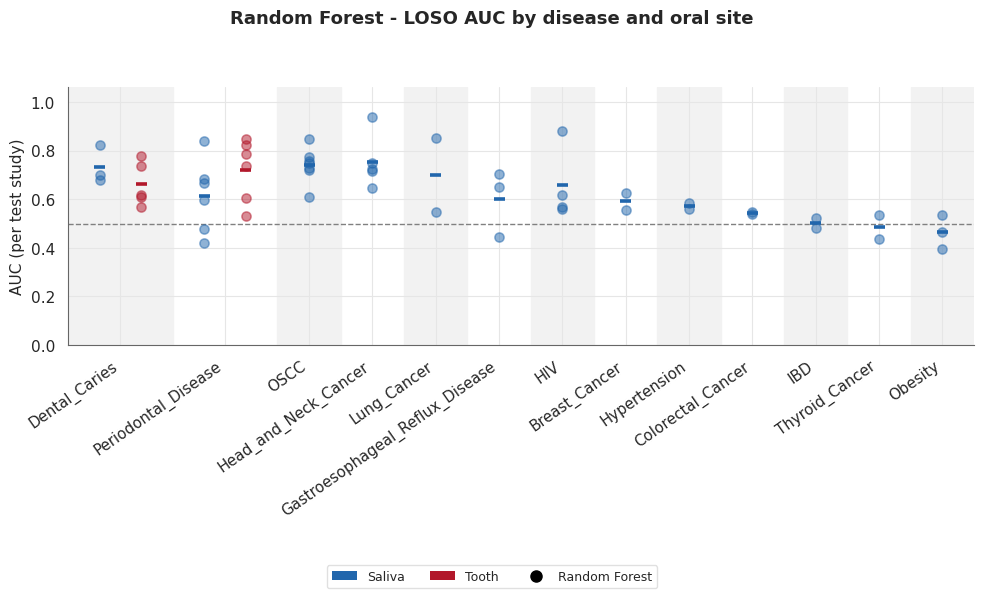

In [102]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
from matplotlib.patches import Patch
from sklearn.metrics import roc_auc_score

# =============================================================================
# PART 1 -- build the RF AUC table (kept in memory as rf_long)
# =============================================================================

# ------------------------------ CONFIG ---------------------------------------
RUN_INFO   = "run_info_genus.csv"          # columns: site, disease, study
RESULT_DIR = "result"                # where the prediction csv files live
RF_FILE    = os.path.join(RESULT_DIR, "RF_results_lso.csv")
OUTPUT_DIR = "result"                # where the (optional) summary csv files go
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Site tokens to drop from the whole analysis (as they appear in run_info).
EXCLUDE_SITES = {"oral_mucosa"}

# Map plot display name -> the site token used in filenames / run_info / groups.
SITE_TOKENS = {
    "Saliva":      "saliva",
    "Tooth":       "tooth",
    "Oral mucosa": "oral_mucosa",
}
TOKEN_TO_DISPLAY = {v: k for k, v in SITE_TOKENS.items()}

# ---- Ground-truth labels ----------------------------------------------------
META_PATH      = "meta_genus.tsv"
META_ID_COL    = "sample_id"   # sample id column; must match SampleID / sampel_id
META_LABEL_COL = "group"       # binary target column (case=1 / control=0)


def load_labels() -> pd.Series:
    """Return a Series: sample_id -> binary label (0/1)."""
    sep = "\t" if META_PATH.lower().endswith((".tsv", ".txt")) else ","
    meta = pd.read_csv(META_PATH, sep=sep)
    missing = [c for c in (META_ID_COL, META_LABEL_COL) if c not in meta.columns]
    if missing:
        raise KeyError(
            f"{missing} not found in {META_PATH}. "
            f"Available columns: {list(meta.columns)}"
        )
    labels = meta[META_LABEL_COL]
    labels.index = meta[META_ID_COL].astype(str)
    return labels[~labels.index.duplicated(keep="first")]


def safe_auc(y_true: pd.Series, y_score: pd.Series) -> float:
    """AUC that returns NaN instead of raising on degenerate inputs."""
    df = pd.DataFrame({"y": y_true.values, "s": y_score.values}).dropna()
    if len(df) < 2 or df["y"].nunique() < 2:
        return np.nan
    return roc_auc_score(df["y"], df["s"])


# ---- Load inputs ------------------------------------------------------------
run_info = pd.read_csv(RUN_INFO)
run_info.columns = [c.strip().lower() for c in run_info.columns]   # site/disease/study
run_info = run_info[~run_info["site"].isin(EXCLUDE_SITES)].copy()  # drop excluded sites
labels = load_labels()

# ---- Random Forest: a single file, split by the `group` column --------------
# group looks like "<site>_<disease>_<study>". We rebuild the expected group
# from run_info instead of splitting the string (disease names have underscores).
rf_raw = pd.read_csv(RF_FILE)                       # sampel_id, group, pred_prob
rf_raw["group"] = rf_raw["group"].astype(str)

rf_records = []
for _, r in run_info.iterrows():
    site, disease, study = str(r["site"]), str(r["disease"]), str(r["study"])
    group = f"{site}_{disease}_{study}"
    sub = rf_raw[rf_raw["group"] == group]
    if sub.empty:
        print(f"[RF] no rows for group, skipped: {group}")
        continue
    y_score = sub.set_index(sub["sampel_id"].astype(str))["pred_prob"]
    y_true = labels.reindex(y_score.index)
    rf_records.append(
        {"site": site, "disease": disease, "test_study": study,
         "auc": safe_auc(y_true, y_score)}
    )
rf_long = pd.DataFrame(rf_records)

# ---- (Optional) also write per-site summary tables to disk ------------------
cols = ["disease", "test_study", "auc"]
for display, token in SITE_TOKENS.items():
    if token in EXCLUDE_SITES:
        continue
    (rf_long[rf_long["site"] == token][cols]
        .to_csv(os.path.join(OUTPUT_DIR, f"rf_loso_auc_all_diseases_genus_{token}.csv"),
                index=False))
    print(f"[write] {token}: RF={len(rf_long[rf_long['site'] == token])} rows")


# =============================================================================
# PART 2 -- plot (single row), RF only
# =============================================================================

SITE_COLORS = {'Saliva': '#2166AC',       # blue
               'Tooth': '#B2182B',        # red
               'Oral mucosa': '#1B7837'}  # green

# ---- Model styling: only RF is drawn ----------------------------------------
MODELS        = ['RF']
MODEL_MARKERS = {'RF': 'o'}              # filled circle
MODEL_FILL    = {'RF': True}             # filled marker in the site colour
ANCHOR_MODELS = ['RF']
POINT_ALPHA = 0.5
# Layout (in data units)
SITE_SLOT = 0.75      # width reserved for one site inside a disease group
GROUP_GAP = 0.40      # empty space between two disease groups
MEAN_HALFWIDTH = 0.10

# Single model -> centred inside the site slot
MODEL_OFFSETS = {'RF': 0.0}

# Single-row layout
N_ROWS = 1               # number of stacked rows of subplots
FIG_ROW_HEIGHT = 3.4     # figure inches per row
INCHES_PER_UNIT = 0.95   # figure inches per data unit of x-axis
MIN_WIDTH, MAX_WIDTH = 8.0, 22.0

MARK_BEST_SITE = False     # star above the best site per disease (RF mean)

# ---------------------------------- BUILD LONG TABLE FROM MEMORY -------------
rf = rf_long.dropna(subset=['auc']).copy()
rf['model'] = 'RF'

data = rf.copy()
data['site'] = data['site'].map(TOKEN_TO_DISPLAY)   # token -> display name
data = data.dropna(subset=['site']).copy()          # drop unmapped / excluded sites

# Keep only diseases present for the anchor model (RF) within each site
kept = []
for site_display, g in data.groupby('site'):
    shared = set(g[g.model == 'RF']['disease'])
    kept.append(g[g['disease'].isin(shared)])
data = pd.concat(kept, ignore_index=True)

# Display sites actually present, in the configured order
SITE_ORDER = [d for d in SITE_TOKENS if d in set(data['site'])]

# ----------------------------------------------------------- DISEASE ORDER ---
rf_all = data[data.model == 'RF']
n_sites = rf_all.groupby('disease')['site'].nunique()
med_auc = rf_all.groupby('disease')['auc'].median()
order = (pd.DataFrame({'n_sites': n_sites, 'med': med_auc})
         .sort_values(['n_sites', 'med'], ascending=[False, False])
         .index.tolist())

# Which sites are actually present for each disease
present_sites = {
    d: [s for s in SITE_ORDER
        if not data[(data.disease == d) & (data.site == s)].empty]
    for d in order
}

# ---------------------------------- SPLIT DISEASES INTO N_ROWS BALANCED ROWS -
def disease_width(d):
    """Data-unit width occupied by one disease group (incl. trailing gap)."""
    return len(present_sites[d]) * SITE_SLOT + GROUP_GAP


def split_contiguous(items, n):
    """Split an ordered list into n contiguous groups with balanced total width."""
    widths = [disease_width(d) for d in items]
    target = sum(widths) / n if n else sum(widths)
    rows, cur, cur_w = [], [], 0.0
    for i, (d, w) in enumerate(zip(items, widths)):
        cur.append(d)
        cur_w += w
        rows_left_after = n - len(rows) - 1
        items_left = len(items) - i - 1
        # close the row once we reach the target, keeping >=1 item per remaining row
        if len(rows) < n - 1 and cur_w >= target and items_left > rows_left_after:
            rows.append(cur)
            cur, cur_w = [], 0.0
    if cur:
        rows.append(cur)
    while len(rows) < n:          # pad with empty rows if needed
        rows.append([])
    return rows


rows = split_contiguous(order, N_ROWS)

# Row width in data units (drop the trailing GROUP_GAP of the last group)
def row_units(row_order):
    return sum(disease_width(d) for d in row_order) - GROUP_GAP if row_order else 0.0

max_units = max((row_units(r) for r in rows), default=1.0)

# Tick font sized to the busiest row
max_per_row = max((len(r) for r in rows), default=1)
tick_fs = float(np.clip(140.0 / max(max_per_row, 1), 8, 12))


# ------------------------------------------------------- RENDER ONE ROW ------
def render_row(ax, row_order):
    site_x, tick_pos, band = {}, [], []
    cursor = 0.0
    for d in row_order:
        k = len(present_sites[d])
        width = k * SITE_SLOT
        for j, s in enumerate(present_sites[d]):
            site_x[(d, s)] = cursor + (j + 0.5) * SITE_SLOT
        tick_pos.append(cursor + width / 2)
        band.append((cursor - GROUP_GAP / 2, cursor + width + GROUP_GAP / 2))
        cursor += width + GROUP_GAP

    for i, (left, right) in enumerate(band):
        if i % 2 == 0:
            ax.axvspan(left, right, color='#F2F2F2', zorder=0)

    for d in row_order:
        for s in present_sites[d]:
            d_site = data[(data.disease == d) & (data.site == s)]
            xc = site_x[(d, s)]

            # Scatter + mean bar for RF
            vals = d_site[d_site.model == 'RF'].set_index('test_study')['auc']
            if len(vals) == 0:
                continue
            x = xc + MODEL_OFFSETS['RF']
            face = SITE_COLORS[s] if MODEL_FILL['RF'] else 'white'
            ax.scatter(np.full(len(vals), x), vals.values,
                       marker=MODEL_MARKERS['RF'], s=44,
                       facecolors=face, edgecolors=SITE_COLORS[s],
                       linewidths=1.1, alpha=POINT_ALPHA, zorder=3)
            ax.hlines(vals.mean(), x - MEAN_HALFWIDTH, x + MEAN_HALFWIDTH,
                      colors=SITE_COLORS[s], linewidths=2.6, zorder=4)

        # Star the best-performing site for this disease (RF mean AUC)
        if MARK_BEST_SITE and len(present_sites[d]) >= 2:
            means = (data[(data.disease == d) & (data.model == 'RF')]
                     .groupby('site')['auc'].mean())
            if not means.empty:
                best = means.idxmax()
                ax.text(site_x[(d, best)], 1.005, '*',
                        ha='center', va='bottom', fontsize=16,
                        color=SITE_COLORS[best], zorder=5)

    ax.axhline(0.5, ls='--', c='grey', lw=1, zorder=2)
    ax.set_ylabel('AUC (per test study)')
    ax.set_ylim(0, 1.06)
    ax.set_yticks(np.arange(0, 1.01, 0.2))
    ax.set_xlim(-GROUP_GAP / 2, max_units + GROUP_GAP / 2)
    ax.set_xticks(tick_pos)
    ax.set_xticklabels(row_order, rotation=35, ha='right', fontsize=tick_fs)
    ax.spines[['top', 'right']].set_visible(False)


# ------------------------------------------------------------------ FIGURE ---
fig, ax = plt.subplots(1, 1, figsize=(10, 6))

render_row(ax, rows[0])

# ---------------------------------------------- LEGEND -----
handles = [Patch(facecolor=SITE_COLORS[s], edgecolor='none', label=s) for s in SITE_ORDER]
handles += [
    mlines.Line2D([], [], marker='o', linestyle='None', markersize=8,
                  markerfacecolor='black', markeredgecolor='black',
                  label='Random Forest'),
]
if MARK_BEST_SITE:
    handles.append(mlines.Line2D([], [], color='black', marker='*', linestyle='None',
                                 markersize=9, label='Best site (RF mean)'))

fig.legend(handles=handles, loc='lower center', ncol=4, fontsize=9,
           frameon=True, framealpha=0.9, edgecolor='#DDDDDD',
           bbox_to_anchor=(0.5, 0.005))

fig.suptitle('Random Forest - LOSO AUC by disease and oral site',
             fontsize=13, fontweight='bold')
fig.tight_layout(rect=[0, 0.10, 1, 0.94])
# plt.savefig(os.path.join(OUTPUT_DIR, "loso_rf_1row_genus.png"),
#             dpi=200, bbox_inches="tight")
plt.show()

### Oral and gut paired project

# Part 2 — Paired oral–gut projects

These studies sampled **both oral and gut sites from the same cohorts**, which lets us ask a
different question: for a given disease, is the oral or the gut microbiome more predictive?  
same genera

## Load the paired dataset and apply quality control

We load the paired `.biom` table and metadata and apply the same QC as before (drop rare genera,
drop low-depth samples, re-sync metadata), then remove samples with missing or `"Other"` labels.

In [106]:
table = biom.load_table("../../data/oral-gut-pair-v2-qc/biom_oral_gut_pair_v2_qc.biom")
table = aggregate_to_genus(table)
metadata = pd.read_csv("../../data/oral-gut-pair-v2-qc/metadata_oral_gut_pair_v2_merge_qc.csv", low_memory=False)
sid = metadata.sample_id.values
table.filter(sid, axis="sample")
table.remove_empty()
# fid = table.ids(axis="observation")
# prevalence = table.nonzero_counts(axis="observation")
# table = table.filter(fid[prevalence > 50], axis='observation', inplace=False)
# table.remove_empty()
sid_reads = table.sum(axis="sample")
sid = table.ids(axis="sample")
table = table.filter(sid[sid_reads > 1000], axis='sample', inplace=False)
table.remove_empty()

sid = table.ids(axis="sample")
metadata = metadata.loc[[i in sid for i in metadata.sample_id.values]]

In [107]:
metadata = metadata.loc[metadata.status_cleaned.notna()]
metadata = metadata.loc[metadata.status_cleaned != "Other"]

In [108]:
metadata = metadata.set_index("sample_id")
metadata['group'] = [0 if i == "HC" else 1 for i in metadata.status_cleaned.values]
metadata.to_csv("meta_oral_gut_genus.tsv", sep="\t")

In [109]:
metadata.head()

,pair_id,pair_time_point,pair_bioproject,pair_type,pair_sample_number,pair_subject_number,bioproject,subject_id,age,age_info,...,platform_cleaned,sequencing_region_cleaned,country_cleaned,continent_group,site_cleaned,site_group_cleaned,disease_study_cleaned,status_cleaned,is_time_series_cleaned,group
sample_id,,,,,,,,,,,,,,,,,,,,,
ERR261883,PRJEB1799_FS_28,NaN,PRJEB1799,single pair,169,169,PRJEB1799,FS_28,46.0,NaN,...,Illumina GAIIx,V2,United States,North America,tongue,Oral,No,HC,no,0
ERR261954,PRJEB1799_FS_32,NaN,PRJEB1799,single pair,169,169,PRJEB1799,FS_32,30.0,NaN,...,Illumina GAIIx,V2,United States,North America,tongue,Oral,No,HC,no,0
ERR261960,PRJEB1799_FS_37,NaN,PRJEB1799,single pair,169,169,PRJEB1799,FS_37,33.0,NaN,...,Illumina GAIIx,V2,United States,North America,tongue,Oral,No,HC,no,0
ERR262224,PRJEB1799_FS_79,NaN,PRJEB1799,single pair,169,169,PRJEB1799,FS_79,41.0,NaN,...,Illumina GAIIx,V2,United States,North America,tongue,Oral,No,HC,no,0
ERR262420,PRJEB1799_FS_117,NaN,PRJEB1799,single pair,169,169,PRJEB1799,FS_117,29.0,NaN,...,Illumina GAIIx,V2,United States,North America,tongue,Oral,No,HC,no,0


## Keep sufficiently-sized study × site × status groups

We count samples per (project, body site, disease status) and keep only groups with **more than
10 samples**, then collect the surviving project IDs. Later we require a project to have all
**four** expected groups present (both sites × both HC/disease) before evaluating it, so the
oral-vs-gut comparison is always made on the same cohort.

In [110]:
metadata = metadata.reset_index()

In [111]:
md_summary = pd.DataFrame(metadata.groupby(["pair_bioproject", "site_group_cleaned", "status_cleaned"])["sample_id"].count())
md_summary = md_summary.loc[md_summary.sample_id > 10]

In [114]:
md_summary

sample_id
pair_bioproject site_group_cleaned status_cleaned                
PRJDB9093       Gut                HC                          13
                                   HIV                         52
                Oral               HC                          11
                                   HIV                         52
PRJEB11425      Gut                ICU                         23
...                                                           ...
PRJNA799190     Oral               HC                          12
PRJNA834584     Gut                HC                          29
                Oral               HC                          47
PRJNA851957     Oral               Alzheimer's Disease         45
PRJNA865362     Oral               HC                          20

[61 rows x 1 columns]

In [112]:
project_id = np.unique([i[0] for i in md_summary.index.values])

In [113]:
N_SPLITS = 5
run_site = []
run_study = []
run_fold = []
for i in project_id:
    if md_summary.loc[i].shape[0] != 4:
        continue
    print(i)
    for site in ["Gut", "Oral"]:
        metadata_pick = metadata.loc[metadata.pair_bioproject == i].copy()
        metadata_pick = metadata_pick.loc[metadata_pick.site_group_cleaned == site].copy()
        metadata_pick["label"] = (metadata_pick["status_cleaned"] != "HC").astype(int)
        sid = metadata_pick.sample_id.values
        y   = metadata_pick["label"].values.astype(int)
        cls_count = np.bincount(y, minlength=2)
        if len(np.unique(y)) < 2 or cls_count.min() < N_SPLITS:
            print(f"[SKIP] study {i} / {site}: "
                  f"n={len(y)} pos={int(y.sum())} cannot run {N_SPLITS}-fold stratified CV")
            continue

        ### filter table
        table_pick = table.filter(sid, axis="sample", inplace=False)
        fid = table_pick.ids(axis="observation")
        prevalence = table_pick.nonzero_counts(axis="observation") 
        table_pick = table_pick.filter(fid[prevalence > 2], axis='observation', inplace=False)
        table_pick.norm(axis='sample')
        if table_pick.shape[1] == 0:
            continue
        sid = table_pick.ids(axis="sample")
        
        skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=42)
        for fold, (tr_idx, te_idx) in enumerate(skf.split(sid, y), start=1):
            train_sid,  Y_all  = sid[tr_idx], y[tr_idx].astype(np.float32)
            test_sid, Y_test = sid[te_idx], y[te_idx].astype(np.float32)
            # Test fold not both-class -> AUC undefined, record NaN
            if len(np.unique(Y_test)) < 2:
                print(f"  study {i}/{site} fold{fold}: test fold not both-class, skip")
                continue
            run_site.append(site)
            run_study.append(i)
            run_fold.append(fold)
            train_biom = table_pick.filter(train_sid, axis="sample", inplace=False)
            test_biom = table_pick.filter(test_sid, axis="sample", inplace=False)

            print(f"train table: {train_biom.shape}, test table: {test_biom.shape}")

            with biom.util.biom_open(f"data/five_fold_genus_train_{site.replace(' ', '_')}_{i}_{fold}.biom", 'w') as f:
                train_biom.to_hdf5(f, 'example')
            with biom.util.biom_open(f"data/five_fold_genus_test_{site.replace(' ', '_')}_{i}_{fold}.biom", 'w') as f:
                test_biom.to_hdf5(f, 'example')

PRJDB9093
train table: (308, 52), test table: (308, 13)
train table: (308, 52), test table: (308, 13)
train table: (308, 52), test table: (308, 13)
train table: (308, 52), test table: (308, 13)
train table: (308, 52), test table: (308, 13)
train table: (165, 50), test table: (165, 13)
train table: (165, 50), test table: (165, 13)
train table: (165, 50), test table: (165, 13)
train table: (165, 51), test table: (165, 12)
train table: (165, 51), test table: (165, 12)
PRJEB23853
train table: (410, 93), test table: (410, 24)
train table: (410, 93), test table: (410, 24)
train table: (410, 94), test table: (410, 23)
train table: (410, 94), test table: (410, 23)
train table: (410, 94), test table: (410, 23)
train table: (590, 114), test table: (590, 29)
train table: (590, 114), test table: (590, 29)
train table: (590, 114), test table: (590, 29)
train table: (590, 115), test table: (590, 28)
train table: (590, 115), test table: (590, 28)
PRJEB25569
train table: (266, 52), test table: (266, 1

In [86]:
run_info = pd.DataFrame({"site": run_site, "fold": run_fold, "study": run_study})
run_info.to_csv("run_info_oral_gut_genus.csv", index=None)

## Final comparison: per-disease boxplots

One panel per disease. Within each panel the x-axis is the study and the boxes are grouped by
**site × model** (Gut/Oral × DeepPhylo/RF): colour encodes the site and shade encodes the model
(dark = DeepPhylo, light = RF). Individual fold AUCs are overlaid as jittered points, and the
dashed line marks chance (0.5). This lets us read off, for each disease and study, whether
DeepPhylo improves on Random Forest and whether the oral or gut site carries more signal.

[built] RF rows=30


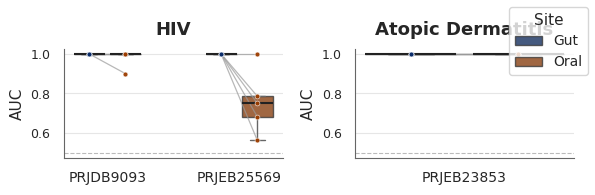

In [115]:
"""
Five-fold CV, paired Oral vs Gut samples: RF only.

PART 1 builds df_all_rf in memory from the raw prediction files:
    run_info_oral_gut_genus.csv                      -> site / fold / study
    result/RF_results_five_fold.csv            -> RF (pred_prob)
    meta_oral_gut_genus.tsv                          -> TRUE case/control labels

One AUC is computed per (site, study, fold); the 5 folds form the box.
PART 2 plots, per disease/study, the Gut vs Oral boxes and connects each
fold's Gut point to its matching Oral point with a line.
"""

import math
import os
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_auc_score

# =============================================================================
# PART 1 -- build df_all_rf  (RF only)
# =============================================================================

# ------------------------------------------------------------------ CONFIG ---
RUN_INFO   = "run_info_oral_gut_genus.csv"        # columns: site, fold, study
RESULT_DIR = "result"

# ---- Ground-truth labels ----------------------------------------------------
META_PATH      = "meta_oral_gut_genus.tsv"
META_ID_COL     = "sample_id"        # sample id column; must match SampleID
META_LABEL_COL  = "group"            # binary target column (case=1 / control=0)
META_STATUS_COL = "status_cleaned"   # disease / HC label column, used for titles


def load_labels() -> pd.Series:
    """Return a Series: sample_id -> binary label (0/1)."""
    sep = "\t" if META_PATH.lower().endswith((".tsv", ".txt")) else ","
    meta = pd.read_csv(META_PATH, sep=sep)
    missing = [c for c in (META_ID_COL, META_LABEL_COL) if c not in meta.columns]
    if missing:
        raise KeyError(
            f"{missing} not found in {META_PATH}. "
            f"Available columns: {list(meta.columns)}"
        )
    labels = meta[META_LABEL_COL]
    labels.index = meta[META_ID_COL].astype(str)
    return labels[~labels.index.duplicated(keep="first")]


def load_status() -> pd.Series:
    """Return a Series: sample_id -> status_cleaned (disease name or 'HC')."""
    sep = "\t" if META_PATH.lower().endswith((".tsv", ".txt")) else ","
    meta = pd.read_csv(META_PATH, sep=sep)
    missing = [c for c in (META_ID_COL, META_STATUS_COL) if c not in meta.columns]
    if missing:
        raise KeyError(
            f"{missing} not found in {META_PATH}. "
            f"Available columns: {list(meta.columns)}"
        )
    status = meta[META_STATUS_COL].astype(str)
    status.index = meta[META_ID_COL].astype(str)
    return status[~status.index.duplicated(keep="first")]


def safe_auc(y_true: pd.Series, y_score: pd.Series) -> float:
    """AUC that returns NaN instead of raising on degenerate inputs."""
    df = pd.DataFrame({"y": y_true.values, "s": y_score.values}).dropna()
    if len(df) < 2 or df["y"].nunique() < 2:
        return np.nan
    return roc_auc_score(df["y"], df["s"])


def _fold_str(v) -> str:
    """Fold as a bare integer string ('1'), tolerant of int/float/str input."""
    try:
        return str(int(v))
    except (ValueError, TypeError):
        return str(v).strip()


# ---- Load inputs ------------------------------------------------------------
run_info = pd.read_csv(RUN_INFO)
run_info.columns = [c.strip().lower() for c in run_info.columns]   # site / fold / study
labels = load_labels()
status = load_status()

# ---- RF: one row-group per (site, study, fold) ------------------------------
rf_raw = pd.read_csv("result/RF_results_five_fold.csv")            # sampel_id, group, pred_prob
rf_raw["group"] = rf_raw["group"].astype(str)

rf_records = []
for _, r in run_info.iterrows():
    site, study, fold = str(r["site"]).strip(), str(r["study"]).strip(), _fold_str(r["fold"])
    group = f"{site}_{study}_{fold}"
    sub = rf_raw[rf_raw["group"] == group]
    if sub.empty:
        print(f"[RF] no rows for group, skipped: {group}")
        continue
    sids = sub["sampel_id"].astype(str)
    y_score = sub.set_index(sids)["pred_prob"]
    y_true = labels.reindex(y_score.index)

    # Disease name for the title: look up this group's samples in the metadata
    # by sample id, then take the non-HC value from status_cleaned.
    grp_status = status.reindex(y_score.index).dropna()
    non_hc = grp_status[grp_status.str.upper() != "HC"]
    disease_name = non_hc.mode().iloc[0] if not non_hc.empty else study

    rf_records.append(
        {"site": site, "study": study, "fold": fold,
         "disease": disease_name, "auc": safe_auc(y_true, y_score)}
    )
df_all_rf = pd.DataFrame(rf_records)

# Drop rows where AUC could not be computed (single-class / no-label folds).
df_all_rf = df_all_rf.dropna(subset=["auc"]).reset_index(drop=True)

assert not df_all_rf.empty, (
    "No AUC values were computed. Check META_ID_COL / META_LABEL_COL and that "
    "sample ids in the prediction files match the metadata."
)
print(f"[built] RF rows={len(df_all_rf)}")


# =============================================================================
# PART 2 -- plot: per-disease Gut vs Oral boxes, folds connected by lines
# =============================================================================

# x = study, boxes grouped by site (Gut / Oral), RF only.
# For each fold, the Gut point is connected to its matching Oral point.
# Points sit exactly at each box center (no horizontal jitter/spread).

# -- INPUT --
combined = df_all_rf.copy()
combined["model"] = "RF"

# -- Global style --
sns.set_theme(style="whitegrid", context="notebook")
mpl.rcParams.update({
    "font.family":     "DejaVu Sans",
    "axes.titlesize":  13, "axes.titleweight": "bold",
    "axes.labelsize":  11, "axes.edgecolor":   "#666666",
    "axes.linewidth":  0.8,
    "grid.color":      "#E6E6E6", "grid.linewidth": 0.8,
    "xtick.labelsize": 10, "ytick.labelsize":  9,
})

site_order = ["Gut", "Oral"]
palette = {
    "Gut":  "#0B2D6B",
    "Oral": "#9C3D00",
}

# -- Spacing parameters --
BOX_WIDTH = 0.55
BOX_GAP   = 0.15
N_HUES    = len(site_order)             # 2
SLOT_W    = BOX_WIDTH / N_HUES          # width allocated per hue group


def box_center_offset(h_idx: int) -> float:
    """Offset of hue box center from the category tick (matches seaborn dodge)."""
    return -BOX_WIDTH / 2 + (h_idx + 0.5) * SLOT_W


gut_off  = box_center_offset(site_order.index("Gut"))
oral_off = box_center_offset(site_order.index("Oral"))

diseases = combined["disease"].unique()
n = len(diseases); ncols = 2; nrows = math.ceil(n / ncols)
fig, axes = plt.subplots(nrows, ncols,
                         figsize=(ncols * 3, nrows * 2),
                         squeeze=False)
axes = axes.flatten()

handles, labels = None, None

for i, disease in enumerate(diseases):
    ax = axes[i]
    sub = combined[combined["disease"] == disease]

    # Explicit study order so boxplot and scatter share the same x mapping
    study_order = list(sub["study"].unique())
    study_to_x  = {s: j for j, s in enumerate(study_order)}

    # -- Box plot --
    sns.boxplot(
        data=sub, x="study", y="auc",
        hue="site", hue_order=site_order,
        order=study_order,          # anchor x-axis order
        ax=ax,
        width=BOX_WIDTH,
        gap=BOX_GAP,
        showfliers=False,
        palette=palette,
        linewidth=1.0,
        boxprops=dict(alpha=0.8, edgecolor="#3a3a3a"),
        medianprops=dict(color="#222222", linewidth=1.5),
        whiskerprops=dict(color="#666666", linewidth=1.0),
        capprops=dict(color="#666666", linewidth=1.0),
    )

    # -- Per-fold paired points + connecting lines (no jitter) --
    for study in study_order:
        x_tick = study_to_x[study]
        s_sub  = sub[sub["study"] == study]

        gut  = s_sub[s_sub["site"] == "Gut"].groupby("fold")["auc"].mean()
        oral = s_sub[s_sub["site"] == "Oral"].groupby("fold")["auc"].mean()

        all_folds = sorted(set(gut.index) | set(oral.index), key=lambda v: int(v))

        # Points sit at the box center; same x for every fold (no spread).
        xg = x_tick + gut_off
        xo = x_tick + oral_off

        for fold in all_folds:
            has_g = fold in gut.index
            has_o = fold in oral.index

            # connecting line: Gut fold -> matching Oral fold
            if has_g and has_o:
                ax.plot([xg, xo], [gut[fold], oral[fold]],
                        color="#9A9A9A", lw=0.9, alpha=0.7, zorder=2)

            # scatter points
            if has_g:
                ax.scatter([xg], [gut[fold]], color=palette["Gut"],
                           s=3.5 ** 2, alpha=0.95,
                           edgecolors="white", linewidths=0.4, zorder=3)
            if has_o:
                ax.scatter([xo], [oral[fold]], color=palette["Oral"],
                           s=3.5 ** 2, alpha=0.95,
                           edgecolors="white", linewidths=0.4, zorder=3)

    ax.set_title(str(disease), pad=10)
    ax.set_xlabel(""); ax.set_ylabel("AUC")
    ax.grid(axis="x", visible=False)
    ax.axhline(0.5, color="#BBBBBB", ls="--", lw=0.8, zorder=0)
    sns.despine(ax=ax)

    if handles is None:
        handles, labels = ax.get_legend_handles_labels()
    if ax.get_legend() is not None:
        ax.get_legend().remove()

# -- Shared legend --
for j in range(n, len(axes)):
    axes[j].axis("off")

if n < len(axes):
    axes[n].legend(handles, labels, title="Site", loc="center",
                   frameon=True, fontsize=11, title_fontsize=12, markerscale=1.3)
else:
    fig.legend(handles, labels, title="Site", loc="upper right",
               frameon=True, fontsize=10, title_fontsize=11)

fig.tight_layout() 
# plt.savefig(os.path.join(RESULT_DIR, "fivefold_oral_gut_rf_paired_genus.png"),
#             dpi=200, bbox_inches="tight")
plt.show()

# Part 3 within-continent and leave-one-continent-out

## Generating Cross-Study Train/Test Splits for Oral Microbiome Classification

This step builds the train/test `.biom` tables used to evaluate disease classifiers on oral microbiome data, along with a manifest describing every split. It loops over four oral sampling sites (**saliva, tooth, tongue, oral mucosa**) and, for each site, produces splits under two evaluation schemes.

### 1. Base filtering
For each site, the sample metadata is loaded and filtered to keep only samples that:
- have a known, non-`"Other"` disease status (`status_cleaned`),
- appear in the working sample-ID set (`sid`),
- come from the current sampling site, and
- have a known continent/region (`continent_group`).

### 2. Study-level requirements
- **HC + disease requirement:** A study (`bioproject_id`) is kept only if it contains both healthy controls (`HC`) *and* at least one disease group. This ensures every study can support a case–control comparison.
- **One study → one continent:** Each study is assigned to a single continent (the one holding the majority of its samples), so no individual study is ever split across continents.
- **Minimum group size:** Each `(study, status)` group must have **more than 5 samples** to be usable.

### 3. Per-disease split construction
For every disease (excluding `HC`), the code identifies *valid studies* — those where, within a single bioproject, both `HC` and that disease each have >5 samples. A disease is only processed if it has **at least 2 valid studies**. Two complementary splitting schemes are then applied:

**(A) Within-continent, leave-one-study-out (`wc`)**
Within each continent that has ≥2 studies, one study is held out as the **test set** while the remaining studies in that same continent form the **training set**. This measures generalization to a *new study within a familiar region*.

**(B) Leave-one-continent-out (`loco`)**
If the disease spans ≥2 continents, one entire continent is held out as the **test set** and all studies from the other continents are used for **training**. This measures generalization to an *entirely unseen geographic region*.

### 4. Feature-table handling and output
For each split, the corresponding samples are pulled from the `biom` feature table. The training table is emptied of all-zero features, and the test table is restricted to the same feature set as training (so both share identical features). Each split is written to disk as `train_*.biom` / `test_*.biom` with a descriptive filename encoding the site, disease, continent, and held-out study.

### 5. Run manifest
Finally, all splits are collected into a `runs` DataFrame recording the **site, disease, continent, held-out test study, and split type** (`wc` or `loco`). This manifest drives the downstream model-training loop.

In [118]:
table = biom.load_table("../../data/metadata-and-biom-v2-qc/biom_oral_qc_dedup.biom")
table = aggregate_to_genus(table)
metadata = pd.read_csv("../../data/metadata-and-biom-v2-qc/metadata_oral_qc_dedup.tsv", sep="\t", low_memory=False)
sid = metadata.sample_id.values
table.filter(sid, axis="sample")
table.remove_empty()
sid_reads = table.sum(axis="sample")
sid = table.ids(axis="sample")
table = table.filter(sid[sid_reads > 1000], axis='sample', inplace=False)
table.remove_empty()

sid = table.ids(axis="sample")
metadata = metadata.loc[[i in sid for i in metadata.sample_id.values]]

In [123]:
import numpy as np
import pandas as pd
import biom

# ---------------- Parameters ----------------
META_PATH = "../../data/metadata-and-biom-v2-qc/metadata_oral_qc_dedup.tsv"
CONTINENT_COL  = "continent_group"   # column representing continent/region in metadata
MIN_CASE_TOTAL = 30                  # minimum pooled case samples across matched BPs
MIN_HC_TOTAL   = 30                  # minimum pooled HC samples across matched BPs
MIN_MATCHED_BP = 2                   # minimum number of matched BPs
ABUND_THRESH   = 0.01                # keep a genus if mean relative abundance >= 1% in any cohort
COHORT_COL     = "bioproject_id"     # definition of "cohort" for the abundance filter
RENORM_AFTER_FILTER = False          # whether to renormalize each sample to 1 after genus filtering

oral_sites = ['saliva', 'tooth', 'tongue', 'oral mucosa']

sid_all = sid          # samples present in the biom table (protect from being overwritten)

# run manifest
run_site, run_disease, run_continent, run_test_study, run_split_type = [], [], [], [], []


def clean(x):
    return str(x).replace(' ', '_')


def prep_table(sample_ids, meta_sub, thresh=ABUND_THRESH, cohort_col=COHORT_COL):
    """Subset table -> convert to relative abundance -> keep genera whose mean
    relative abundance is >= thresh in at least one cohort."""
    tp = table.filter(sample_ids, axis="sample", inplace=False)
    tp.norm(axis="sample", inplace=True)

    fid = np.asarray(tp.ids(axis="observation"))
    sids = np.asarray(tp.ids(axis="sample"))
    mat = pd.DataFrame(tp.matrix_data.toarray(), index=fid, columns=sids)  # genus x sample
    cohort = meta_sub.set_index("sample_id").loc[sids, cohort_col].astype(str).values

    # mean relative abundance, genus x cohort
    mean_by_cohort = mat.T.groupby(cohort).mean().T
    keep_fid = fid[(mean_by_cohort.max(axis=1) >= thresh).values]
    print(f"    genus: {len(fid)} -> {len(keep_fid)} "
          f"(mean relative abundance >= {thresh:.0%} in at least one cohort)")
    if len(keep_fid) == 0:
        return None

    tp = tp.filter(keep_fid, axis="observation", inplace=False)
    if RENORM_AFTER_FILTER:
        tp.norm(axis="sample", inplace=True)
    return tp


def dump(train_biom, test_biom, base):
    with biom.util.biom_open(f"data/genus_train_{base}.biom", 'w') as f:
        train_biom.to_hdf5(f, 'example')
    with biom.util.biom_open(f"data/genus_test_{base}.biom", 'w') as f:
        test_biom.to_hdf5(f, 'example')


for site in oral_sites:
    print(f"\n########## SITE: {site} ##########")

    metadata = pd.read_csv(META_PATH, sep="\t", low_memory=False)
    metadata = metadata.loc[metadata.status_cleaned.notna()]
    metadata = metadata.loc[metadata.status_cleaned != "Other"]
    metadata = metadata.loc[metadata.sample_id.isin(set(sid_all))]
    metadata = metadata.loc[metadata.site_cleaned == site]
    metadata = metadata.loc[metadata[CONTINENT_COL].notna()]

    if metadata.empty:
        print("  No samples for this site, skipping...")
        continue

    # one continent per study (majority vote, so a study is never split)
    proj2cont = metadata.groupby("bioproject_id")[CONTINENT_COL].agg(
        lambda x: x.value_counts().index[0])

    # sample counts per (BP, status); no minimum per group within a BP
    counts = (metadata.groupby(["bioproject_id", "status_cleaned"])["sample_id"]
                      .count().reset_index(name="n"))

    for s in sorted(counts.status_cleaned.unique()):
        if s == "HC":
            continue
        print(f"\n=== Disease: {s} ===")

        # ---- 1) Matched BPs: contain both HC and this disease ----
        sub = counts[counts.status_cleaned.isin(["HC", s])]
        matched_bp = (sub.groupby("bioproject_id")["status_cleaned"].nunique()
                         .pipe(lambda x: x[x == 2]).index.tolist())

        if len(matched_bp) < MIN_MATCHED_BP:
            print(f"  Only {len(matched_bp)} matched BP(s) (< {MIN_MATCHED_BP}), skipping...")
            continue

        # ---- 2) Pooled case / HC sample sizes across all matched BPs ----
        sub = sub[sub.bioproject_id.isin(matched_bp)]
        n_case = int(sub.loc[sub.status_cleaned == s, "n"].sum())
        n_hc   = int(sub.loc[sub.status_cleaned == "HC", "n"].sum())
        print(f"  matched BP: {len(matched_bp)} | pooled case={n_case}, HC={n_hc}")

        # if n_case < MIN_CASE_TOTAL or n_hc < MIN_HC_TOTAL:
        #     print(f"  Pooled sample size too small "
        #           f"(need case>={MIN_CASE_TOTAL}, HC>={MIN_HC_TOTAL}), skipping...")
        #     continue

        # ---- 3) Samples of this matched cohort ----
        meta_s = metadata.loc[
            metadata.bioproject_id.isin(matched_bp)
            & metadata.status_cleaned.isin(["HC", s])
        ].copy()

        proj_cont  = {p: proj2cont[p] for p in matched_bp}
        conts      = sorted(set(proj_cont.values()))
        cont2projs = {c: [p for p in matched_bp if proj_cont[p] == c] for c in conts}
        print("  studies per continent: " +
              ", ".join(f"{c}:{len(v)}" for c, v in cont2projs.items()))

        # ===== (A) within-continent: leave-one-study-out inside each continent =====
        for c, projs in cont2projs.items():
            if len(projs) < 2:
                continue
            print(f"  [within] {c}: {len(projs)} studies")

            meta_wc = meta_s[meta_s.bioproject_id.isin(projs)]
            table_pick = prep_table(meta_wc['sample_id'].values, meta_wc)
            if table_pick is None or table_pick.shape[1] == 0:
                continue
            # generate_normalize_tree(table_pick, f"data/phylogeny_normalize_wc_{clean(site)}_{clean(s)}_{clean(c)}.nwk")

            for j in projs:
                train_study = [p for p in projs if p != j]
                train_sid = meta_wc[meta_wc.bioproject_id.isin(train_study)]['sample_id'].values
                test_sid  = meta_wc[meta_wc.bioproject_id == j]['sample_id'].values

                train_biom = table_pick.filter(train_sid, axis="sample", inplace=False)
                test_biom  = table_pick.filter(test_sid,  axis="sample", inplace=False)
                print(f"    test={j}  train {train_biom.shape}  test {test_biom.shape}")

                dump(train_biom, test_biom, f"wc_{clean(site)}_{clean(s)}_{clean(c)}_{j}")

                run_site.append(clean(site)); run_disease.append(clean(s))
                run_continent.append(clean(c)); run_test_study.append(str(j))
                run_split_type.append("wc")

        # ===== (B) leave-one-continent-out, tested study-by-study =====
        # train = all studies outside continent c; test = ONE study inside c (one fold per study)
        if len(conts) < 2:
            print("  Spans only 1 continent, skipping leave-one-continent-out")
            continue

        table_pick = prep_table(meta_s['sample_id'].values, meta_s)
        if table_pick is None or table_pick.shape[1] == 0:
            continue
        # generate_normalize_tree(table_pick, f"data/phylogeny_normalize_loco_{clean(site)}_{clean(s)}.nwk")

        for c in conts:
            train_projs = [p for p in matched_bp if proj_cont[p] != c]
            if len(train_projs) == 0:
                continue
            train_sid  = meta_s[meta_s.bioproject_id.isin(train_projs)]['sample_id'].values
            train_biom = table_pick.filter(train_sid, axis="sample", inplace=False)

            print(f"  [LOCO] held-out continent={c}: "
                  f"train {len(train_projs)} studies {train_biom.shape}, "
                  f"{len(cont2projs[c])} test study/studies")

            for j in cont2projs[c]:
                test_sid  = meta_s[meta_s.bioproject_id == j]['sample_id'].values
                test_biom = table_pick.filter(test_sid, axis="sample", inplace=False)
                print(f"    test-study={j}  test {test_biom.shape}")

                dump(train_biom, test_biom, f"loco_{clean(site)}_{clean(s)}_{clean(c)}_{j}")

                run_site.append(clean(site)); run_disease.append(clean(s))
                run_continent.append(clean(c)); run_test_study.append(str(j))
                run_split_type.append("loco")

runs = pd.DataFrame({
    "site": run_site, "disease": run_disease, "continent": run_continent,
    "test_study": run_test_study, "split_type": run_split_type,
})


########## SITE: saliva ##########
  usable diseases: Dental Caries(1 studies), OSCC(5 studies), Periodontal Disease(6 studies), Oral Mucositis(1 studies), Oral Verrucous Hyperplasia(1 studies), Head and Neck Cancer(3 studies)
  [cross-disease] train=Dental Caries (HC+Dental Caries, (403, 21))  test=OSCC (HC+OSCC, (403, 351))
  [cross-disease] train=Dental Caries (HC+Dental Caries, (382, 21))  test=Periodontal Disease (HC+Periodontal Disease, (382, 321))


Exception ignored in: <bound method IPythonKernel._clean_thread_parent_frames of <ipykernel.ipkernel.IPythonKernel object at 0x7f1be77f63d0>>
Traceback (most recent call last):
  File "/home/dongbiao/.conda/envs/jupyter_notebook/lib/python3.9/site-packages/ipykernel/ipkernel.py", line 775, in _clean_thread_parent_frames
    def _clean_thread_parent_frames(
KeyboardInterrupt: 


  [cross-disease] train=Dental Caries (HC+Dental Caries, (100, 21))  test=Oral Mucositis (HC+Oral Mucositis, (100, 19))
  [cross-disease] train=Dental Caries (HC+Dental Caries, (144, 21))  test=Oral Verrucous Hyperplasia (HC+Oral Verrucous Hyperplasia, (144, 48))
  [cross-disease] train=Dental Caries (HC+Dental Caries, (228, 21))  test=Head and Neck Cancer (HC+Head and Neck Cancer, (228, 695))
  [cross-disease] train=OSCC (HC+OSCC, (403, 351))  test=Dental Caries (HC+Dental Caries, (403, 21))


KeyboardInterrupt: 

In [89]:
runs.to_csv("run_info_continent_genus.csv", index=False)

/home/dongbiao/tmp/ipykernel_357340/1229626947.py:65: DtypeWarning: Columns (15) have mixed types. Specify dtype option on import or set low_memory=False.
  meta = pd.read_csv(META_PATH, sep=sep)


[RF] no rows for group, skipped: wc_tooth_Periodontal_Disease_South_America_PRJNA660085
[RF] no rows for group, skipped: loco_tooth_Periodontal_Disease_South_America_PRJNA660085
[built] 92 AUC rows (wc=41, loco=51)


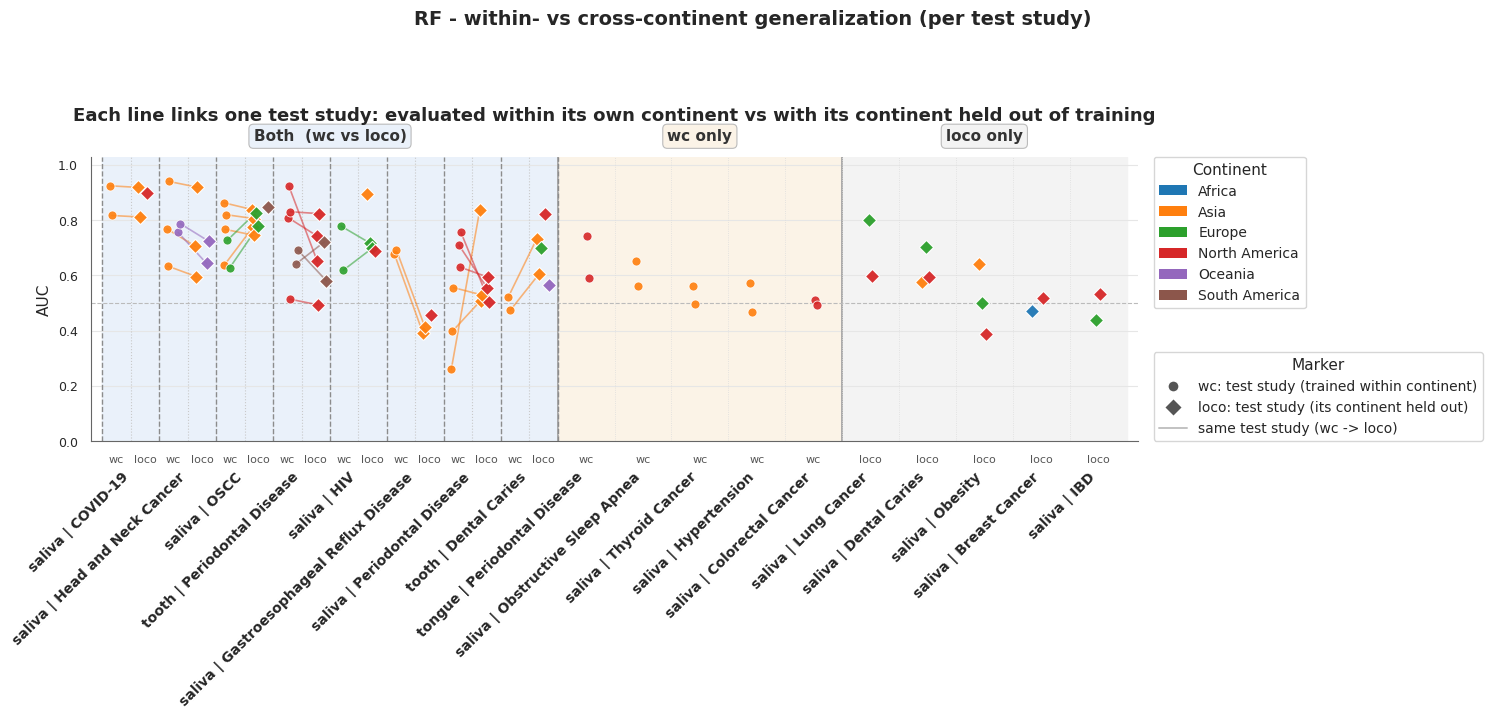

In [116]:
"""
RF / DeepPhylo -- within-continent (wc, analysis A) vs leave-one-continent-out
(loco, analysis B), drawn in ONE panel for easy comparison.

*** Changes in this version ***
1) Each loco fold now holds out one continent and tests on a SINGLE study from
   that continent, so wc and loco share one naming scheme:
       <split>_<site>_<disease>_<continent>_<test_study>
2) All mean markers are removed (the former continent-mean triangles are gone).
   Every point on the panel is the AUC of one test study.
3) In the "Both (wc vs loco)" section, each connector links the SAME test study
   under the two training setups (within-continent vs cross-continent), so the
   slope of a line is that study's change in generalization performance.

Layout: diseases are grouped left-to-right into three sections
    [ 1. BOTH wc + loco ]   |   [ 2. wc only ]   |   [ 3. loco only ]
Each disease occupies one x slot; when both splits exist, wc sits on the left
half of the slot and loco on the right half.
"""

import os
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
from matplotlib.patches import Patch
import seaborn as sns
from sklearn.metrics import roc_auc_score

# =============================================================================
# PART 1 -- build the AUC table
# =============================================================================

# ------------------------------------------------------------------ CONFIG ---
RUN_INFO   = "run_info_continent_genus.csv"    # site, disease, continent, test_study, split_type
RESULT_DIR = "result"
RF_RESULTS = "result/RF_results_continent.csv"

# ---- Ground-truth labels ----------------------------------------------------
META_PATH      = "meta_genus.tsv"
META_ID_COL    = "sample_id"   # sample id column; must match SampleID (SRR...)
META_LABEL_COL = "group"       # binary target column (case=1 / control=0)

SPLIT_LABEL = {"wc": "Within-continent", "loco": "Cross-continent"}

DROP_SITES = ["oral_mucosa"]   # sites to exclude from the panel


def _to_binary(s: pd.Series) -> pd.Series:
    """Coerce a label column to 0/1 floats, accepting common string encodings."""
    if s.dtype != object:
        return pd.to_numeric(s, errors="coerce")
    mapping = {
        "case": 1, "control": 0, "disease": 1, "healthy": 0, "patient": 1,
        "positive": 1, "negative": 0, "yes": 1, "no": 0,
        "true": 1, "false": 0, "1": 1, "0": 0,
    }
    return s.astype(str).str.strip().str.lower().map(mapping)


def load_labels() -> pd.Series:
    """Return a Series: sample_id -> binary label (0/1)."""
    sep = "\t" if META_PATH.lower().endswith((".tsv", ".txt")) else ","
    meta = pd.read_csv(META_PATH, sep=sep)
    missing = [c for c in (META_ID_COL, META_LABEL_COL) if c not in meta.columns]
    if missing:
        raise KeyError(
            f"{missing} not found in {META_PATH}. "
            f"Available columns: {list(meta.columns)}"
        )
    labels = _to_binary(meta[META_LABEL_COL])
    labels.index = meta[META_ID_COL].astype(str)
    return labels[~labels.index.duplicated(keep="first")]


def safe_auc(y_true: pd.Series, y_score: pd.Series) -> float:
    """AUC that returns NaN instead of raising on degenerate inputs."""
    d = pd.DataFrame({"y": y_true.values, "s": y_score.values}).dropna()
    if len(d) < 2 or d["y"].nunique() < 2:
        return np.nan
    return roc_auc_score(d["y"], d["s"])


# ---- Load inputs ------------------------------------------------------------
run_info = pd.read_csv(RUN_INFO, dtype={"test_study": str})
run_info.columns = [c.strip().lower() for c in run_info.columns]
labels = load_labels()

rf_raw = pd.read_csv(RF_RESULTS)
rf_raw["group"] = rf_raw["group"].astype(str)

records = []
for _, r in run_info.iterrows():
    split     = str(r["split_type"]).strip()
    site      = str(r["site"]).strip()
    disease   = str(r["disease"]).strip()
    continent = str(r["continent"]).strip()
    study     = str(r["test_study"]).strip()

    # wc and loco now share one scheme: <split>_<site>_<disease>_<continent>_<test_study>
    group = f"{split}_{site}_{disease}_{continent}_{study}"

    sub = rf_raw[rf_raw["group"] == group]
    if sub.empty:
        print(f"[RF] no rows for group, skipped: {group}")
        continue

    sids    = sub["sampel_id"].astype(str)
    y_score = sub.set_index(sids)["pred_prob"]
    y_true  = labels.reindex(y_score.index)

    records.append({
        "site": site, "disease": disease, "continent": continent,
        "test_study": study, "split_type": split,
        "split": SPLIT_LABEL.get(split, split),
        "auc": safe_auc(y_true, y_score),
    })

df = pd.DataFrame(records).dropna(subset=["auc"]).reset_index(drop=True)
df = df.loc[~df.site.isin(DROP_SITES)].reset_index(drop=True)

assert not df.empty, (
    "No AUC values were computed. Check META_ID_COL / META_LABEL_COL, the group "
    "naming, and that sample ids in the prediction file match the metadata."
)
print(f"[built] {len(df)} AUC rows "
      f"(wc={(df.split_type=='wc').sum()}, loco={(df.split_type=='loco').sum()})")


# =============================================================================
# PART 2 -- single panel: one point per test study, no means.
#           [both wc+loco]  |  [wc only]  |  [loco only]
#           connectors link the SAME test study across wc / loco
# =============================================================================

sns.set_theme(style="whitegrid", context="notebook")
mpl.rcParams.update({
    "font.family":     "DejaVu Sans",
    "axes.titlesize":  13, "axes.titleweight": "bold",
    "axes.labelsize":  11, "axes.edgecolor":   "#666666",
    "axes.linewidth":  0.8,
    "grid.color":      "#E6E6E6", "grid.linewidth": 0.8,
    "xtick.labelsize": 10, "ytick.labelsize":  9,
})

# x categories: disease (prefixed with site only if more than one site present)
multi_site = df["site"].nunique() > 1
df["xcat"] = (df["site"] + " | " + df["disease"]) if multi_site else df["disease"]
df["test_study"] = df["test_study"].astype(str)

# which splits each disease actually has (may be wc-only or loco-only)
present = {x: set(df[df.xcat == x]["split_type"]) for x in df["xcat"].unique()}

# --- grouping / ordering -----------------------------------------------------
GROUP_BOTH, GROUP_WC, GROUP_LOCO = 0, 1, 2
GROUP_LABEL = {GROUP_BOTH: "Both  (wc vs loco)",
               GROUP_WC:   "wc only",
               GROUP_LOCO: "loco only"}
GROUP_TINT  = {GROUP_BOTH: "#EAF1FA", GROUP_WC: "#FBF3E7", GROUP_LOCO: "#F3F3F3"}


def group_rank(x):
    p = present[x]
    if p == {"wc", "loco"}:
        return GROUP_BOTH          # paired -> most informative, goes first
    if p == {"wc"}:
        return GROUP_WC
    return GROUP_LOCO              # loco only


def wc_level(x):
    """Ordering scalar for the paired section: mean AUC over all wc folds of
    this disease. Used only to sort the x axis; nothing is drawn for it."""
    v = df[(df.xcat == x) & (df.split_type == "wc")]["auc"]
    return v.mean() if len(v) else np.nan


def sort_key(x):
    g = group_rank(x)
    if g == GROUP_BOTH:
        return (g, -wc_level(x), x)
    return (g, -df[df.xcat == x]["auc"].mean(), x)


all_xcats = sorted(df["xcat"].unique(), key=sort_key)
pos = {x: i for i, x in enumerate(all_xcats)}
group_of = {x: group_rank(x) for x in all_xcats}

# contiguous section spans (group_rank, start_idx, end_idx) in slot coordinates
sections = []
if all_xcats:
    start = 0
    for i in range(1, len(all_xcats) + 1):
        if i == len(all_xcats) or group_of[all_xcats[i]] != group_of[all_xcats[start]]:
            sections.append((group_of[all_xcats[start]], start, i - 1))
            start = i

# consistent continent colours + within-cluster horizontal dodge
continents = sorted(df["continent"].unique())
K = len(continents)
pal = sns.color_palette("tab10", n_colors=max(K, 3))
cont_color = {c: pal[i] for i, c in enumerate(continents)}

HALF       = 0.25                            # when both: wc=pos-HALF, loco=pos+HALF
SUBSTEP    = min(0.40 / max(K, 1), 0.10)     # horizontal dodge between continents
STUDY_SPAN = SUBSTEP * 0.55                  # total spread of studies within a continent
cont_dodge = {c: (i - (K - 1) / 2) * SUBSTEP for i, c in enumerate(continents)}


def study_offsets(studies):
    """Small horizontal offset per study within a continent. wc and loco reuse
    the same offsets so that the connectors line up."""
    n = len(studies)
    if n <= 1:
        return {s: 0.0 for s in studies}
    step = STUDY_SPAN / (n - 1)
    return {s: (i - (n - 1) / 2) * step for i, s in enumerate(studies)}


def sub_centers(x):
    """Centre x of the wc / loco sub-clusters (a lone side is centred on the slot)."""
    i = pos[x]
    both = present[x] == {"wc", "loco"}
    return ((i - HALF) if both else i, (i + HALF) if both else i)


ncols = len(all_xcats)
fig, ax = plt.subplots(figsize=(15, 7))

# ---- section backgrounds + separators ---------------------------------------
for g, s0, s1 in sections:
    ax.axvspan(s0 - 0.5, s1 + 0.5, color=GROUP_TINT[g], zorder=0)
for _, _, s1 in sections[:-1]:
    ax.axvline(s1 + 0.5, color="#AAAAAA", ls="-", lw=1.4, zorder=1)
for x, i in pos.items():
    if i > 0:
        ax.axvline(i - 0.5, color="#DDDDDD", ls=":", lw=0.6, zorder=1)
    if present[x] == {"wc", "loco"}:
        ax.axvline(i, color="#C9C9C9", ls=":", lw=0.8, zorder=1)
for g, s0, s1 in sections:
    if g != GROUP_BOTH:
        continue
    for i in range(s0, s1 + 1):
        ax.axvline(i - 0.5, color="#8C8C8C", ls="--", lw=1.0, zorder=1)
    ax.axvline(s1 + 0.5, color="#8C8C8C", ls="--", lw=1.0, zorder=1)

# ---- data: one point per test study + same-study wc->loco connectors --------
for x in all_xcats:
    sub          = df[df["xcat"] == x]
    wc_c, loco_c = sub_centers(x)
    paired       = present[x] == {"wc", "loco"}

    for cont in continents:
        csub = sub[sub.continent == cont]
        if csub.empty:
            continue
        col     = cont_color[cont]
        base_d  = cont_dodge[cont]
        studies = sorted(csub["test_study"].unique())
        off     = study_offsets(studies)

        wc_map = (csub[csub.split_type == "wc"]
                  .set_index("test_study")["auc"].to_dict())
        lc_map = (csub[csub.split_type == "loco"]
                  .set_index("test_study")["auc"].to_dict())

        for st in studies:
            dx     = base_d + off[st]
            xw, xl = wc_c + dx, loco_c + dx
            a_wc   = wc_map.get(st)
            a_lc   = lc_map.get(st)

            # same test study: wc -> loco connector
            if paired and a_wc is not None and a_lc is not None:
                ax.plot([xw, xl], [a_wc, a_lc], color=col, lw=1.2, alpha=0.55,
                        zorder=2, solid_capstyle="round")

            if a_wc is not None:
                ax.scatter([xw], [a_wc], marker="o", s=42, facecolors=col,
                           edgecolors="white", linewidths=0.6, alpha=0.90, zorder=3)
            if a_lc is not None:
                ax.scatter([xl], [a_lc], marker="D", s=52, facecolors=col,
                           edgecolors="white", linewidths=0.8, alpha=0.95, zorder=4)

ax.axhline(0.5, color="#BBBBBB", ls="--", lw=0.8, zorder=1)
ax.set_ylim(0, 1.03)
ax.set_yticks(np.arange(0, 1.01, 0.2))
ax.set_ylabel("AUC")
ax.set_xlim(-0.7, ncols - 0.3)

# ---- two-level x labels: wc/loco sub-labels, then 45-deg disease name -------
sub_ticks, sub_labels = [], []
for x in all_xcats:
    wc_c, loco_c = sub_centers(x)
    if present[x] == {"wc", "loco"}:
        sub_ticks  += [wc_c, loco_c]
        sub_labels += ["wc", "loco"]
    elif "wc" in present[x]:
        sub_ticks.append(wc_c)
        sub_labels.append("wc")
    else:
        sub_ticks.append(loco_c)
        sub_labels.append("loco")
ax.set_xticks(sub_ticks)
ax.set_xticklabels(sub_labels, fontsize=8, color="#555555")

trans = ax.get_xaxis_transform()            # x=data, y=axes-fraction
for x, i in pos.items():
    ax.text(i, -0.10, x.replace("_", " "), transform=trans,
            ha="right", va="top", rotation=45, fontsize=10, fontweight="bold")

# ---- section headers above the panel ---------------------------------------
for g, s0, s1 in sections:
    ax.text((s0 + s1) / 2, 1.045, GROUP_LABEL[g], transform=trans,
            ha="center", va="bottom", fontsize=11, fontweight="bold",
            color="#333333",
            bbox=dict(boxstyle="round,pad=0.3", fc=GROUP_TINT[g],
                      ec="#BBBBBB", lw=0.8))

ax.grid(axis="x", visible=False)
sns.despine(ax=ax)

# ---- legend: continents (colour) + marker meaning --------------------------
cont_handles = [Patch(facecolor=cont_color[c], edgecolor="none",
                      label=c.replace("_", " ")) for c in continents]
marker_handles = [
    mlines.Line2D([], [], color="#555555", marker="o", linestyle="None",
                  markersize=8, markeredgecolor="white",
                  label="wc: test study (trained within continent)"),
    mlines.Line2D([], [], color="#555555", marker="D", linestyle="None",
                  markersize=9, markeredgecolor="white",
                  label="loco: test study (its continent held out)"),
    mlines.Line2D([], [], color="#999999", linestyle="-", linewidth=1.4,
                  alpha=0.6, label="same test study (wc -> loco)"),
]
leg1 = ax.legend(handles=cont_handles, title="Continent",
                 loc="upper left", bbox_to_anchor=(1.015, 1.0),
                 bbox_transform=ax.transAxes,
                 frameon=True, fontsize=10, title_fontsize=11,
                 borderaxespad=0.0)
ax.add_artist(leg1)
ax.legend(handles=marker_handles, title="Marker",
          loc="lower left", bbox_to_anchor=(1.015, 0.0),
          bbox_transform=ax.transAxes,
          frameon=True, fontsize=10, title_fontsize=11,
          borderaxespad=0.0)

ax.set_title("Each line links one test study: evaluated within its own continent "
             "vs with its continent held out of training", pad=26)
fig.suptitle("RF - within- vs cross-continent generalization (per test study)",
             fontsize=14, fontweight="bold", y=1.06)

fig.tight_layout()
# plt.savefig(os.path.join(RESULT_DIR, "continent_A_vs_B_combined_genus.png"),
#             dpi=200, bbox_inches="tight")
plt.show()

### Part 4 : Cross-disease: training disease A, testing disease B

## Generating Cross-Disease Transfer Train/Test Splits (Within Site)

This step builds train/test `.biom` tables for evaluating **cross-disease transfer** — training a classifier on one oral disease and testing whether it generalizes to a *different* disease. It loops over three oral sampling sites (**saliva, tooth, tongue**) and, within each site, creates one split for every ordered pair of usable diseases. A run manifest describing all splits is produced at the end.

### 1. Target diseases
A fixed list of oral diseases is defined for the transfer analysis (`ORAL_DISEASES`), including conditions such as Dental Caries, OSCC, Periodontal Disease, Oral Submucous Fibrosis, Oral Mucositis, Oral Verrucous Hyperplasia, Aphthous, Oral Lichen Planus, and Head and Neck Cancer. This list can be edited to include or exclude conditions (e.g., dropping Head and Neck Cancer for a strictly-oral analysis).

### 2. Base filtering (per site)
For each site, the metadata is loaded and filtered to keep only samples that:
- have a known, non-`"Other"` disease status (`status_cleaned`),
- appear in the working sample-ID set (`sid`), and
- come from the current sampling site.

### 3. Identifying usable diseases
- **Minimum group size:** Each `(study, status)` group must have **more than 5 samples**, computed *after* the site filter.
- **Valid studies per disease:** For a given disease, a study is "valid" only if, within that single bioproject, both `HC` and that disease each have >5 samples at this site.
- A disease is marked **usable** at this site if it has at least one valid study.
- If fewer than **2 usable diseases** exist at a site, no cross-disease pair can be formed and the site is skipped.

### 4. Building disease sample sets
For each usable disease, the sample set consists of `HC` + that disease, restricted to the disease's valid studies within the current site. This becomes the pool from which train and test sets are drawn.

### 5. Cross-disease pairing (all ordered pairs)
For every ordered pair of usable diseases **(A → B)** where A ≠ B:
- **Train** = `HC + A` samples; **Test** = `HC + B` samples.
- **Leakage guard:** Any sample appearing in both train and test (which can happen when a study contributes HC to both diseases at the same site) is removed from the test set. If no test samples remain afterward, the pair is skipped.
- The feature tables are pulled from the `biom` table; the training table is emptied of all-zero features, and the test table is restricted to the same feature set so both share identical features.
- Each split is written to disk as `train_*.biom` / `test_*.biom`, with a filename encoding the site and the train/test disease pair (`cd_{site}_train_{A}_test_{B}`).

### 6. Run manifest
All splits are collected into a `runs_cd` DataFrame recording, for each pair: the **site**, **train disease**, **test disease**, total train/test sample counts (`n_train`, `n_test`), the number of case (non-HC) samples in each (`n_train_case`, `n_test_case`), and a fixed `split_type` of `cross_disease_within_site`. This manifest drives the downstream model-training loop.

In [124]:
oral_sites = ['saliva', 'tooth', 'tongue']

# Typical oral diseases for cross-disease transfer (edit as needed)
ORAL_DISEASES = [
    'Dental Caries', 'OSCC', 'Periodontal Disease',
    'Oral Submucous Fibrosis', 'Oral Mucositis',
    'Oral Verrucous Hyperplasia', 'Aphthous', 'Oral Lichen Planus',
    'Head and Neck Cancer',   # includes oral cavity; remove if you want strictly-oral
]

def clean(x):
    return str(x).replace(' ', '_')

# run manifest (now includes site)
run_site, run_train, run_test = [], [], []
run_ntrain, run_ntest, run_ntrain_case, run_ntest_case = [], [], [], []

for site in oral_sites:
    print(f"\n########## SITE: {site} ##########")

    # ---------- Base filtering, same criteria, now per site ----------
    metadata = pd.read_csv(
        "../../data/metadata-and-biom-v2-qc/metadata_oral_qc_dedup.tsv",
        sep="\t", low_memory=False)
    metadata = metadata.loc[metadata.status_cleaned.notna()]
    metadata = metadata.loc[metadata.status_cleaned != "Other"]
    metadata = metadata.loc[[i in sid for i in metadata.sample_id]]
    metadata = metadata.loc[metadata.site_cleaned == site]     # restrict to this site
    if metadata.empty:
        print("  no samples at this site, skipping")
        continue

    # Each (bioproject, status) needs > 5 samples -- computed AFTER the site filter
    result = metadata.groupby(["bioproject_id", "status_cleaned"])['sample_id'].count().reset_index()
    result = result.query('sample_id > 5')

    # For each disease, keep only studies where BOTH HC and that disease have > 5 samples at this site
    def valid_studies_for(d):
        pick = result[result['status_cleaned'].isin(["HC", d])]
        two = pick.groupby('bioproject_id')['status_cleaned'].nunique()
        return two[two == 2].index.tolist()

    usable = {}
    for d in ORAL_DISEASES:
        projs = valid_studies_for(d)
        if len(projs) >= 1:
            usable[d] = projs

    if len(usable) < 2:
        print(f"  only {len(usable)} usable disease(s) at this site, "
              f"cannot form a cross-disease pair, skipping")
        continue

    print("  usable diseases: " +
          ", ".join(f"{d}({len(p)} studies)" for d, p in usable.items()))

    # Samples (HC + d) restricted to d's valid studies, within this site
    def disease_samples(d):
        m = metadata[metadata.bioproject_id.isin(usable[d]) &
                     metadata.status_cleaned.isin(["HC", d])]
        return m

    # ---------- Cross-disease: all ordered pairs (train on A, test on B) ----------
    diseases = list(usable.keys())
    for A in diseases:
        mA = disease_samples(A)
        train_sid = mA['sample_id'].values
        for B in diseases:
            if A == B:
                continue
            mB = disease_samples(B)
            test_sid = mB['sample_id'].values

            # Guard against leakage: drop any test sample also present in train
            # (only if a study contributes HC to both A and B at this site)
            overlap = set(train_sid) & set(test_sid)
            if overlap:
                print(f"  [warn] {A}->{B}: {len(overlap)} shared samples removed from test")
                test_sid = np.array([x for x in test_sid if x not in overlap])
            if len(test_sid) == 0:
                print(f"  [skip] {A}->{B}: no test samples left")
                continue
                
            ### filter table
            sid_pick = train_sid.tolist() + test_sid.tolist()
            table_pick = table.filter(sid_pick, axis="sample", inplace=False)
            fid = table_pick.ids(axis="observation")
            prevalence = table_pick.nonzero_counts(axis="observation")
            table_pick = table_pick.filter(fid[prevalence > 2], axis='observation', inplace=False)
            table_pick.norm(axis='sample')
            if table_pick.shape[1] == 0:
                continue
        
            # Build biom tables and align features to the training set
            train_biom = table_pick.filter(train_sid, axis="sample", inplace=False)
            test_biom = table_pick.filter(test_sid, axis="sample", inplace=False)

            n_train_case = int((mA.status_cleaned == A).sum())
            n_test_case  = int((metadata[metadata.sample_id.isin(test_sid)]
                                .status_cleaned == B).sum())

            print(f"  [cross-disease] train={A} (HC+{A}, {train_biom.shape})  "
                  f"test={B} (HC+{B}, {test_biom.shape})")

            base = f"cd_{clean(site)}_train_{clean(A)}_test_{clean(B)}"
            with biom.util.biom_open(f"data/train_{base}.biom", 'w') as f:
                train_biom.to_hdf5(f, 'example')
            with biom.util.biom_open(f"data/test_{base}.biom", 'w') as f:
                test_biom.to_hdf5(f, 'example')

            run_site.append(clean(site))
            run_train.append(clean(A)); run_test.append(clean(B))
            run_ntrain.append(train_biom.shape[1]); run_ntest.append(test_biom.shape[1])
            run_ntrain_case.append(n_train_case); run_ntest_case.append(n_test_case)

# Collect all cross-disease splits for the downstream training loop
runs_cd = pd.DataFrame({
    "site": run_site,
    "train_disease": run_train, "test_disease": run_test,
    "n_train": run_ntrain, "n_test": run_ntest,
    "n_train_case": run_ntrain_case, "n_test_case": run_ntest_case,
    "split_type": "cross_disease_within_site",
})


########## SITE: saliva ##########
  usable diseases: Dental Caries(1 studies), OSCC(5 studies), Periodontal Disease(6 studies), Oral Mucositis(1 studies), Oral Verrucous Hyperplasia(1 studies), Head and Neck Cancer(3 studies)
  [cross-disease] train=Dental Caries (HC+Dental Caries, (403, 21))  test=OSCC (HC+OSCC, (403, 351))
  [cross-disease] train=Dental Caries (HC+Dental Caries, (382, 21))  test=Periodontal Disease (HC+Periodontal Disease, (382, 321))
  [cross-disease] train=Dental Caries (HC+Dental Caries, (100, 21))  test=Oral Mucositis (HC+Oral Mucositis, (100, 19))
  [cross-disease] train=Dental Caries (HC+Dental Caries, (144, 21))  test=Oral Verrucous Hyperplasia (HC+Oral Verrucous Hyperplasia, (144, 48))
  [cross-disease] train=Dental Caries (HC+Dental Caries, (228, 21))  test=Head and Neck Cancer (HC+Head and Neck Cancer, (228, 695))
  [cross-disease] train=OSCC (HC+OSCC, (403, 351))  test=Dental Caries (HC+Dental Caries, (403, 21))
  [cross-disease] train=OSCC (HC+OSCC, (61

In [125]:
runs_cd.to_csv("run_info_cross_disease_genus.csv", index=False)

/home/dongbiao/tmp/ipykernel_357340/2207154532.py:57: DtypeWarning: Columns (15) have mixed types. Specify dtype option on import or set low_memory=False.
  meta = pd.read_csv(META_PATH, sep=sep)


[built] 34 train->test pairs (33 with a valid AUC)


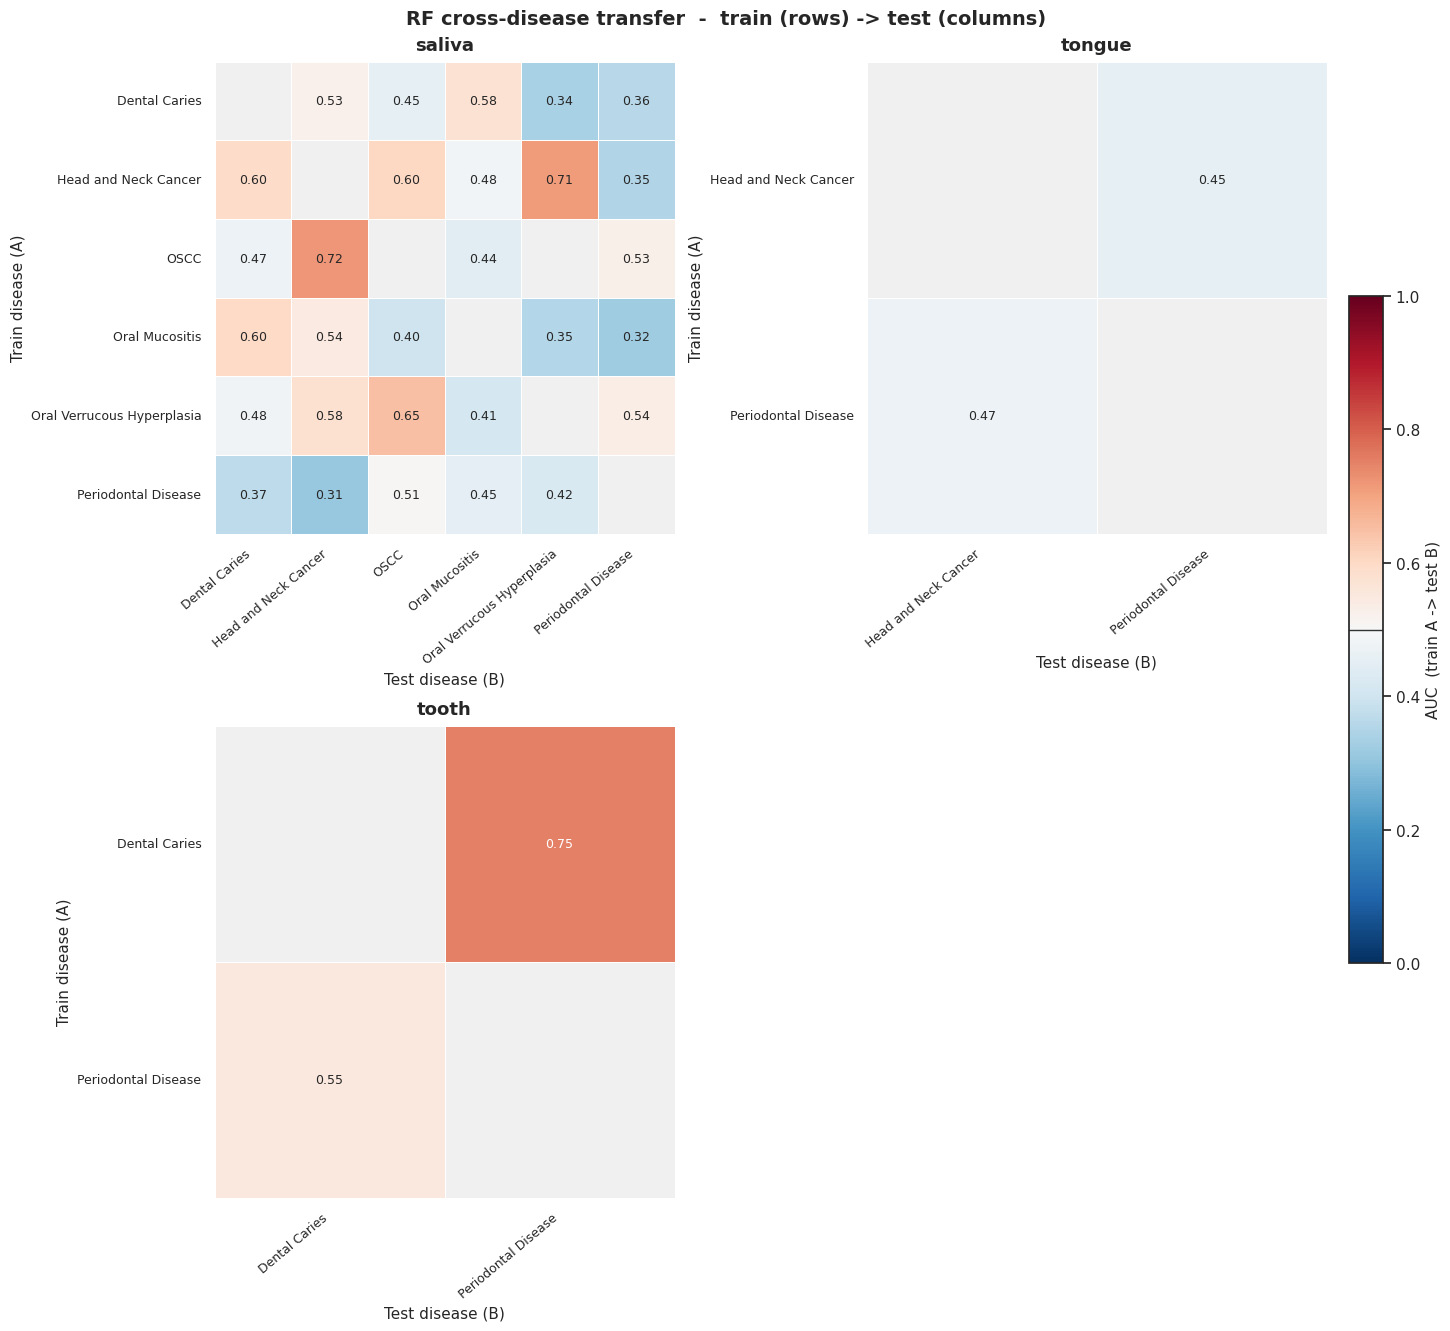

In [126]:
"""
DeepPhylo cross-disease transfer: train on disease A, test on disease B
(all ordered pairs, within each site).

PART 1 -- one AUC per run_info row from the prediction files:
    run_info_cross_disease_genus.csv
        columns include: site, train_disease, test_disease, split_type
    result/predictions_deepphylo_cd_<site>_train_<train_disease>_test_<test_disease>.csv
    meta_genus.tsv  -> TRUE case/control labels (SampleID = ERR...)

PART 2 -- one transfer-matrix heatmap per site:
    rows    = train disease (A)   -- only diseases that actually have results
    columns = test disease  (B)   -- only diseases that actually have results
    colour  = AUC (RdBu_r, 0.5 = white = chance; red better, blue worse)
"""

import math
import os
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
import seaborn as sns
from sklearn.metrics import roc_auc_score

# =============================================================================
# PART 1 -- build the AUC table
# =============================================================================

# ------------------------------------------------------------------ CONFIG ---
RUN_INFO   = "run_info_cross_disease_genus.csv"
RESULT_DIR = "result"

# ---- Ground-truth labels ----------------------------------------------------
META_PATH      = "meta_genus.tsv"
META_ID_COL    = "sample_id"   # sample id column; must match SampleID (ERR...)
META_LABEL_COL = "group"       # binary target column (case=1 / control=0)


def _to_binary(s: pd.Series) -> pd.Series:
    """Coerce a label column to 0/1 floats, accepting common string encodings."""
    if s.dtype != object:
        return pd.to_numeric(s, errors="coerce")
    mapping = {
        "case": 1, "control": 0, "disease": 1, "healthy": 0, "patient": 1,
        "positive": 1, "negative": 0, "yes": 1, "no": 0,
        "true": 1, "false": 0, "1": 1, "0": 0,
    }
    return s.astype(str).str.strip().str.lower().map(mapping)


def load_labels() -> pd.Series:
    """Return a Series: sample_id -> binary label (0/1)."""
    sep = "\t" if META_PATH.lower().endswith((".tsv", ".txt")) else ","
    meta = pd.read_csv(META_PATH, sep=sep)
    missing = [c for c in (META_ID_COL, META_LABEL_COL) if c not in meta.columns]
    if missing:
        raise KeyError(
            f"{missing} not found in {META_PATH}. "
            f"Available columns: {list(meta.columns)}"
        )
    labels = _to_binary(meta[META_LABEL_COL])
    labels.index = meta[META_ID_COL].astype(str)
    return labels[~labels.index.duplicated(keep="first")]


def safe_auc(y_true: pd.Series, y_score: pd.Series) -> float:
    """AUC that returns NaN instead of raising on degenerate inputs."""
    df = pd.DataFrame({"y": y_true.values, "s": y_score.values}).dropna()
    if len(df) < 2 or df["y"].nunique() < 2:
        return np.nan
    return roc_auc_score(df["y"], df["s"])


# ---- Load inputs ------------------------------------------------------------
run_info = pd.read_csv(RUN_INFO)
run_info.columns = [c.strip().lower() for c in run_info.columns]
labels = load_labels()

records = []
# for _, r in run_info.iterrows():
#     site = str(r["site"]).strip()
#     train = str(r["train_disease"]).strip()
#     test = str(r["test_disease"]).strip()
#     path = os.path.join(
#         RESULT_DIR,
#         f"predictions_deepphylo_cd_{site}_train_{train}_test_{test}.csv",
#     )
#     if not os.path.exists(path):
#         print(f"[DeepPhylo] missing, skipped: {path}")
#         continue
#     pred = pd.read_csv(path)                        # SampleID, Prob_1, Pred
#     y_score = pred.set_index(pred["SampleID"].astype(str))["Prob_1"]
#     y_true = labels.reindex(y_score.index)
#     records.append({
#         "site": site, "train_disease": train, "test_disease": test,
#         "auc": safe_auc(y_true, y_score),
#     })

rf_raw = pd.read_csv("result/RF_results_cross_disease.csv")
rf_raw["group"] = rf_raw["group"].astype(str)
records = []
for _, r in run_info.iterrows():
    site = str(r["site"]).strip()
    train = str(r["train_disease"]).strip()
    test = str(r["test_disease"]).strip()

    group = f"cd_{site}_train_{train}_test_{test}"
    sub = rf_raw[rf_raw["group"] == group]
    if sub.empty:
        print(f"[RF] no rows for group, skipped: {group}")
        continue
    sids = sub["sampel_id"].astype(str)
    y_score = sub.set_index(sids)["pred_prob"]
    y_true = labels.reindex(y_score.index)

    records.append({"site": site, "train_disease": train, "test_disease": test,
        "auc": safe_auc(y_true, y_score),
    })
df = pd.DataFrame(records)
assert not df.empty, (
    "No rows built. Check RESULT_DIR / file naming and META_ID_COL / META_LABEL_COL."
)
n_ok = df["auc"].notna().sum()
print(f"[built] {len(df)} train->test pairs ({n_ok} with a valid AUC)")

df.to_csv(os.path.join(RESULT_DIR, "cross_disease_auc_long_genus.csv"), index=False)


# =============================================================================
# PART 2 -- transfer-matrix heatmap(s), one per site
# =============================================================================

sns.set_theme(style="white", context="notebook")
mpl.rcParams.update({
    "font.family":    "DejaVu Sans",
    "axes.titlesize": 13, "axes.titleweight": "bold",
    "axes.labelsize": 11,
})

CMAP, VMIN, VMAX = "RdBu_r", 0.0, 1.0   # 0.5 -> white (chance)

valid = df[df["auc"].notna()]
sites = sorted(valid["site"].unique())

n = len(sites)
ncols = min(n, 2)
nrows = math.ceil(n / ncols)
fig, axes = plt.subplots(nrows, ncols,
                         figsize=(ncols * 7.2, nrows * 6.6),
                         squeeze=False, constrained_layout=True)
axes = axes.flatten()

for i, site in enumerate(sites):
    ax = axes[i]
    sub = valid[valid["site"] == site]

    # keep only diseases that really appear for this site (drop all-empty rows/cols)
    rows = sorted(sub["train_disease"].unique())
    cols = sorted(sub["test_disease"].unique())
    mat = (sub.pivot_table(index="train_disease", columns="test_disease", values="auc")
              .reindex(index=rows, columns=cols))

    sns.heatmap(
        mat, ax=ax, cmap=CMAP, vmin=VMIN, vmax=VMAX,
        annot=True, fmt=".2f", annot_kws={"size": 9},
        linewidths=0.6, linecolor="white",
        mask=mat.isna(), cbar=False, square=False,
    )
    ax.set_facecolor("#F0F0F0")                     # missing pairs within this site
    ax.set_title(site, pad=8)
    ax.set_xlabel("Test disease (B)")
    ax.set_ylabel("Train disease (A)")
    ax.set_xticklabels([t.get_text().replace("_", " ") for t in ax.get_xticklabels()],
                       rotation=40, ha="right", fontsize=9)
    ax.set_yticklabels([t.get_text().replace("_", " ") for t in ax.get_yticklabels()],
                       rotation=0, fontsize=9)

for j in range(n, len(axes)):
    axes[j].axis("off")

# Shared colour bar
sm = ScalarMappable(norm=Normalize(VMIN, VMAX), cmap=CMAP)
sm.set_array([])
cbar = fig.colorbar(sm, ax=axes.tolist(), fraction=0.03, pad=0.02, shrink=0.85)
cbar.set_label("AUC  (train A -> test B)")
cbar.ax.axhline(0.5, color="#333333", lw=1.0)       # mark the chance level

fig.suptitle("RF cross-disease transfer  -  train (rows) -> test (columns)",
             fontsize=14, fontweight="bold")
plt.show()

### Part 5 Learning Curve: training sample size

## Generating Learning-Curve Train/Test Splits

This step builds train/test `.biom` tables for constructing **learning curves** — measuring how classifier performance changes as the number of training studies grows. It runs on a small set of hand-picked, large-sample `(site, disease)` combinations, and for each one it sweeps the number of studies used in training from 2 up to the maximum available. A run manifest describing all splits is produced at the end.

### 1. Configuration
- **`SEED = 42`** fixes the random seed for reproducible study sampling.
- **`N_REPEAT = 3`** sets how many distinct study subsets to draw at each subset size.
- **`LC_TARGETS`** lists the specific `(site, disease)` combinations to analyze — chosen because they have enough samples to support a meaningful curve (e.g., saliva/OSCC, saliva/Head and Neck Cancer, saliva/Periodontal Disease, tooth/Periodontal Disease).

### 2. Distinct-subset sampling helper
`draw_distinct_subsets` returns up to `n_want` distinct k-sized subsets of the available studies. To stay efficient across both small and large pools, it uses two strategies:
- **Small pools** (≤200 possible combinations): enumerate all k-subsets, shuffle, and take the first `n`.
- **Large pools:** rejection-sample random subsets until `n` distinct ones are collected.

This ensures the repeats at each subset size are genuinely different combinations of studies.

### 3. Base filtering (per target)
For each `(site, disease)` target, the metadata is loaded and filtered to keep only samples that:
- have a known, non-`"Other"` disease status (`status_cleaned`),
- appear in the working sample-ID set (`sid`), and
- come from the current site.

### 4. Identifying valid studies
- **Minimum group size:** Each `(study, status)` group must have **more than 5 samples**.
- **Valid studies:** A study (`bioproject_id`) counts only if, within that single bioproject, both `HC` and the target disease each have >5 samples.
- The number of valid studies sets the maximum subset size (`max_k`). If fewer than **2 studies** qualify, no learning curve can be built and the target is skipped.
- Sampling is then restricted to `HC + disease` samples within these valid studies.

### 5. Learning-curve construction
For each subset size **k = 2 … max_k**:
- Draw up to `N_REPEAT` distinct k-study subsets (the "repeats").
- Within each sampled subset, apply **leave-one-study-out**: each study `j` in the subset is held out as the **test set** in turn, while the remaining k−1 studies form the **training set**.
- For every train/test split, the feature tables are pulled from the `biom` table; the training table is emptied of all-zero features, and the test table is restricted to the same feature set so both share identical features.
- Each split is written to disk as `train_*.biom` / `test_*.biom`, with a filename encoding the site, disease, subset size, repeat index, and held-out study (`lc_{site}_{disease}_k{k}_r{rep}_test_{j}`).

### 6. Run manifest
All splits are collected into a `runs_lc` DataFrame recording, for each split: the **site**, **disease**, number of training-pool studies (`n_studies` = k), **repeat** index, the full **subset** of studies used (pipe-joined), the held-out **test study**, and a fixed `split_type` of `learning_curve`. This manifest drives the downstream model-training loop, where results are aggregated across repeats and held-out studies to trace performance as a function of study count.

In [69]:
import numpy as np
import pandas as pd
import random
import biom
from math import comb
from itertools import combinations

SEED = 42
N_REPEAT = 3

ABUND_THRESH = 0.01          # keep a genus if mean relative abundance >= 1% in any cohort
COHORT_COL   = "bioproject_id"   # definition of "cohort" for the abundance filter
RENORM_AFTER_FILTER = True   # renormalize each sample to sum 1 after genus filtering

# One analysis per (site, disease): large-sample combos only
LC_TARGETS = [
    ("saliva", "OSCC"),
    ("saliva", "Head and Neck Cancer"),
    ("saliva", "Periodontal Disease"),
    ("tooth",  "Periodontal Disease"),
]

def clean(x):
    return str(x).replace(' ', '_')

def draw_distinct_subsets(items, k, n_want, rng):
    """Return up to n_want distinct k-subsets of items (as sorted tuples)."""
    total = comb(len(items), k)
    n = min(n_want, total)
    if total <= 200:                      # small: enumerate then sample
        allc = list(combinations(sorted(items), k))
        rng.shuffle(allc)
        return allc[:n]
    seen = set()                          # large: rejection-sample
    while len(seen) < n:
        seen.add(tuple(sorted(rng.sample(items, k))))
    return list(seen)

def prep_table(sample_ids, meta_sub, thresh=ABUND_THRESH, cohort_col=COHORT_COL):
    """Subset table -> total-sum normalize -> keep genera whose mean relative
    abundance is >= thresh in at least one cohort -> renormalize (total sum)."""
    tp = table.filter(sample_ids, axis="sample", inplace=False)
    tp.norm(axis="sample", inplace=True)

    fid  = np.asarray(tp.ids(axis="observation"))
    sids = np.asarray(tp.ids(axis="sample"))
    mat = pd.DataFrame(tp.matrix_data.toarray(), index=fid, columns=sids)  # genus x sample
    cohort = meta_sub.drop_duplicates("sample_id").set_index("sample_id") \
                     .loc[sids, cohort_col].astype(str).values

    # mean relative abundance, genus x cohort
    mean_by_cohort = mat.T.groupby(cohort).mean().T
    keep_fid = fid[(mean_by_cohort.max(axis=1) >= thresh).values]
    if len(keep_fid) == 0:
        return None

    tp = tp.filter(keep_fid, axis="observation", inplace=False)
    if RENORM_AFTER_FILTER:
        tp.norm(axis="sample", inplace=True)   # total sum normalization
    return tp

# run manifest
run_site, run_disease, run_k, run_rep, run_subset, run_test = [], [], [], [], [], []

for site, disease in LC_TARGETS:
    print(f"\n########## SITE: {site} | DISEASE: {disease} ##########")

    # ---------- Base filtering, same criteria as before ----------
    metadata = pd.read_csv(
        "../../data/metadata-and-biom-v2-qc/metadata_oral_qc_dedup.tsv",
        sep="\t", low_memory=False)
    metadata = metadata.loc[metadata.status_cleaned.notna()]
    metadata = metadata.loc[metadata.status_cleaned != "Other"]
    metadata = metadata.loc[[i in sid for i in metadata.sample_id]]
    metadata = metadata.loc[metadata.site_cleaned == site]

    result = metadata.groupby(["bioproject_id", "status_cleaned"])['sample_id'].count().reset_index()
    # Valid studies: within one bioproject, both HC and the disease are present
    pick = result[result['status_cleaned'].isin(["HC", disease])]
    two = pick.groupby('bioproject_id')['status_cleaned'].nunique()
    valid_proj = two[two == 2].index.tolist()
    max_k = len(valid_proj)
    print(f"  valid studies: {max_k} -> {valid_proj}")
    if max_k < 2:
        print("  Fewer than 2 studies, cannot build a learning curve, skipping...")
        continue

    # Restrict to HC + disease samples within valid studies
    meta_d = metadata[metadata.bioproject_id.isin(valid_proj) &
                      metadata.status_cleaned.isin(["HC", disease])]

    rng = random.Random(SEED)

    # ---------- Learning curve: k = 2 .. max_k ----------
    for k in range(2, max_k + 1):
        subsets = draw_distinct_subsets(valid_proj, k, N_REPEAT, rng)
        print(f"  k={k}: {len(subsets)} repeat(s)")
        for rep, subset in enumerate(subsets):
            subset = list(subset)

            # genus filter computed on the k sampled studies
            meta_sub = meta_d[meta_d.bioproject_id.isin(subset)]
            table_pick = prep_table(meta_sub['sample_id'].values, meta_sub)
            if table_pick is None or table_pick.shape[1] == 0:
                print(f"    r{rep}: no genus passed the abundance filter, skipping")
                continue
            print(f"    r{rep}: studies={subset}, genus kept={table_pick.shape[0]}")

            # leave-one-study-out inside the sampled k studies
            for j in subset:
                train_study = [p for p in subset if p != j]
                train_sid = meta_sub[meta_sub.bioproject_id.isin(train_study)]['sample_id'].values
                test_sid  = meta_sub[meta_sub.bioproject_id == j]['sample_id'].values

                train_biom = table_pick.filter(train_sid, axis="sample", inplace=False)
                test_biom  = table_pick.filter(test_sid,  axis="sample", inplace=False)

                base = f"lc_{clean(site)}_{clean(disease)}_k{k}_r{rep}_test_{j}"
                with biom.util.biom_open(f"data/genus_train_{base}.biom", 'w') as f:
                    train_biom.to_hdf5(f, 'example')
                with biom.util.biom_open(f"data/genus_test_{base}.biom", 'w') as f:
                    test_biom.to_hdf5(f, 'example')

                run_site.append(clean(site)); run_disease.append(clean(disease))
                run_k.append(k); run_rep.append(rep)
                run_subset.append("|".join(str(p) for p in subset))
                run_test.append(str(j))

# Collect all learning-curve splits for the downstream training loop
runs_lc = pd.DataFrame({
    "site": run_site, "disease": run_disease,
    "n_studies": run_k, "repeat": run_rep,
    "subset": run_subset, "test_study": run_test,
    "split_type": "learning_curve",
})


########## SITE: saliva | DISEASE: OSCC ##########
  valid studies: 7 -> ['PRJEB18476', 'PRJEB39064', 'PRJNA386665', 'PRJNA700849', 'PRJNA751046', 'PRJNA756784', 'PRJNA997108']
  k=2: 3 repeat(s)
    r0: studies=['PRJNA751046', 'PRJNA997108'], genus kept=37
    r1: studies=['PRJEB18476', 'PRJNA997108'], genus kept=33
    r2: studies=['PRJNA386665', 'PRJNA997108'], genus kept=33
  k=3: 3 repeat(s)
    r0: studies=['PRJNA700849', 'PRJNA751046', 'PRJNA997108'], genus kept=43
    r1: studies=['PRJEB39064', 'PRJNA751046', 'PRJNA997108'], genus kept=50
    r2: studies=['PRJEB39064', 'PRJNA386665', 'PRJNA700849'], genus kept=46
  k=4: 3 repeat(s)
    r0: studies=['PRJEB18476', 'PRJNA386665', 'PRJNA756784', 'PRJNA997108'], genus kept=49
    r1: studies=['PRJEB18476', 'PRJEB39064', 'PRJNA386665', 'PRJNA700849'], genus kept=49
    r2: studies=['PRJEB18476', 'PRJNA386665', 'PRJNA751046', 'PRJNA756784'], genus kept=52
  k=5: 3 repeat(s)
    r0: studies=['PRJEB18476', 'PRJNA700849', 'PRJNA751046',

In [70]:
runs_lc.head()

,site,disease,n_studies,repeat,subset,test_study,split_type
0,saliva,OSCC,2,0,PRJNA751046|PRJNA997108,PRJNA751046,learning_curve
1,saliva,OSCC,2,0,PRJNA751046|PRJNA997108,PRJNA997108,learning_curve
2,saliva,OSCC,2,1,PRJEB18476|PRJNA997108,PRJEB18476,learning_curve
3,saliva,OSCC,2,1,PRJEB18476|PRJNA997108,PRJNA997108,learning_curve
4,saliva,OSCC,2,2,PRJNA386665|PRJNA997108,PRJNA386665,learning_curve


In [71]:
runs_lc.to_csv("run_info_lc_genus.csv", index=False)

/home/dongbiao/tmp/ipykernel_357340/470932773.py:58: DtypeWarning: Columns (15) have mixed types. Specify dtype option on import or set low_memory=False.
  meta = pd.read_csv(META_PATH, sep=sep)


[RF] no rows for group, skipped: lc_saliva_Periodontal_Disease_k2_r0_test_PRJEB50306
[RF] no rows for group, skipped: lc_saliva_Periodontal_Disease_k2_r1_test_PRJNA578492
[RF] no rows for group, skipped: lc_saliva_Periodontal_Disease_k2_r2_test_PRJEB50306
[RF] no rows for group, skipped: lc_saliva_Periodontal_Disease_k2_r2_test_PRJNA721290
[RF] no rows for group, skipped: lc_saliva_Periodontal_Disease_k3_r0_test_PRJEB42371
[RF] no rows for group, skipped: lc_saliva_Periodontal_Disease_k3_r0_test_PRJEB61123
[RF] no rows for group, skipped: lc_saliva_Periodontal_Disease_k3_r0_test_PRJNA721290
[RF] no rows for group, skipped: lc_saliva_Periodontal_Disease_k3_r1_test_PRJNA721290
[RF] no rows for group, skipped: lc_saliva_Periodontal_Disease_k3_r2_test_PRJNA578492
[RF] no rows for group, skipped: lc_saliva_Periodontal_Disease_k3_r2_test_PRJNA721290
[RF] no rows for group, skipped: lc_saliva_Periodontal_Disease_k4_r0_test_PRJEB50306
[RF] no rows for group, skipped: lc_saliva_Periodontal_Dise

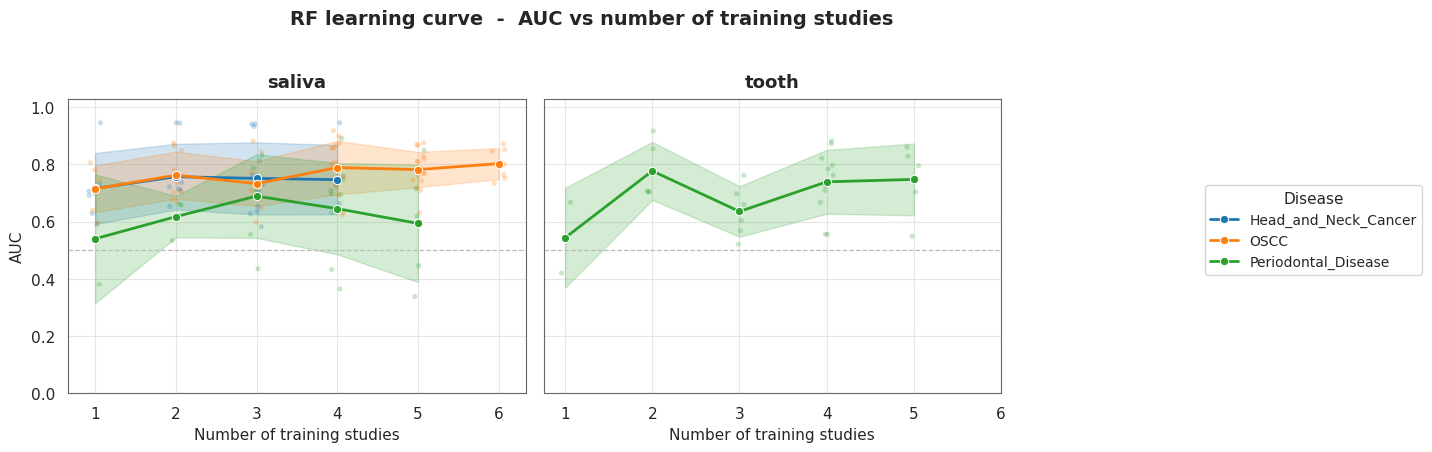

In [51]:
"""
DeepPhylo learning curve: effect of dataset size (number of training studies)
on performance.

PART 1 -- one AUC per run_info row from the prediction files:
    run_info_lc_genus.csv
        columns: site, disease, n_studies, repeat, subset, test_study, split_type
    result/predictions_deepphylo_lc_<site>_<disease>_k<n_studies>_r<repeat>_test_<test_study>.csv
    meta_genus.tsv  -> TRUE case/control labels (SampleID = SRR...)

PART 2 -- AUC vs number of training studies:
    line   = mean AUC per disease at each dataset size
    band   = spread across repeats and held-out studies (std dev)
    dots   = individual (repeat, test_study) AUCs (faint)
    one panel per site.
"""

import math
import os
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_auc_score

# =============================================================================
# PART 1 -- build the AUC table
# =============================================================================

# ------------------------------------------------------------------ CONFIG ---
RUN_INFO   = "run_info_lc_genus.csv"
RESULT_DIR = "result"

# ---- Ground-truth labels ----------------------------------------------------
META_PATH      = "meta_genus.tsv"
META_ID_COL    = "sample_id"   # sample id column; must match SampleID (SRR...)
META_LABEL_COL = "group"       # binary target column (case=1 / control=0)

ERRORBAR = "sd"   # band: "sd" (std dev), "se" (std error), or ("ci", 95)


def _to_binary(s: pd.Series) -> pd.Series:
    """Coerce a label column to 0/1 floats, accepting common string encodings."""
    if s.dtype != object:
        return pd.to_numeric(s, errors="coerce")
    mapping = {
        "case": 1, "control": 0, "disease": 1, "healthy": 0, "patient": 1,
        "positive": 1, "negative": 0, "yes": 1, "no": 0,
        "true": 1, "false": 0, "1": 1, "0": 0,
    }
    return s.astype(str).str.strip().str.lower().map(mapping)


def load_labels() -> pd.Series:
    """Return a Series: sample_id -> binary label (0/1)."""
    sep = "\t" if META_PATH.lower().endswith((".tsv", ".txt")) else ","
    meta = pd.read_csv(META_PATH, sep=sep)
    missing = [c for c in (META_ID_COL, META_LABEL_COL) if c not in meta.columns]
    if missing:
        raise KeyError(
            f"{missing} not found in {META_PATH}. "
            f"Available columns: {list(meta.columns)}"
        )
    labels = _to_binary(meta[META_LABEL_COL])
    labels.index = meta[META_ID_COL].astype(str)
    return labels[~labels.index.duplicated(keep="first")]


def safe_auc(y_true: pd.Series, y_score: pd.Series) -> float:
    """AUC that returns NaN instead of raising on degenerate inputs."""
    df = pd.DataFrame({"y": y_true.values, "s": y_score.values}).dropna()
    if len(df) < 2 or df["y"].nunique() < 2:
        return np.nan
    return roc_auc_score(df["y"], df["s"])


def _int(v) -> str:
    try:
        return str(int(v))
    except (ValueError, TypeError):
        return str(v).strip()


# ---- Load inputs ------------------------------------------------------------
run_info = pd.read_csv(RUN_INFO)
run_info.columns = [c.strip().lower() for c in run_info.columns]
labels = load_labels()

# records = []
# for _, r in run_info.iterrows():
#     site = str(r["site"]).strip()
#     disease = str(r["disease"]).strip()
#     k = _int(r["n_studies"])
#     rep = _int(r["repeat"])
#     test = str(r["test_study"]).strip()

#     path = os.path.join(
#         RESULT_DIR,
#         f"predictions_deepphylo_lc_{site}_{disease}_k{k}_r{rep}_test_{test}.csv",
#     )
#     if not os.path.exists(path):
#         print(f"[DeepPhylo] missing, skipped: {path}")
#         continue
#     pred = pd.read_csv(path)                        # SampleID, Prob_1, Pred
#     y_score = pred.set_index(pred["SampleID"].astype(str))["Prob_1"]
#     y_true = labels.reindex(y_score.index)
#     records.append({
#         "site": site, "disease": disease,
#         "n_studies": int(k),                 # pool size (incl. held-out test study)
#         "n_train_studies": int(k) - 1,       # studies actually used for training
#         "repeat": int(rep), "test_study": test,
#         "auc": safe_auc(y_true, y_score),
#     })

rf_raw = pd.read_csv("result/RF_results_lc.csv")
rf_raw["group"] = rf_raw["group"].astype(str)
records = []
for _, r in run_info.iterrows():
    site = str(r["site"]).strip()
    disease = str(r["disease"]).strip()
    k = _int(r["n_studies"])
    rep = _int(r["repeat"])
    test = str(r["test_study"]).strip()

    group = f"lc_{site}_{disease}_k{k}_r{rep}_test_{test}"
    sub = rf_raw[rf_raw["group"] == group]
    if sub.empty:
        print(f"[RF] no rows for group, skipped: {group}")
        continue
    sids = sub["sampel_id"].astype(str)
    y_score = sub.set_index(sids)["pred_prob"]
    y_true = labels.reindex(y_score.index)

    records.append({
        "site": site, "disease": disease,
        "n_studies": int(k),                 # pool size (incl. held-out test study)
        "n_train_studies": int(k) - 1,       # studies actually used for training
        "repeat": int(rep), "test_study": test,
        "auc": safe_auc(y_true, y_score),
    })
df = pd.DataFrame(records).dropna(subset=["auc"]).reset_index(drop=True)
assert not df.empty, (
    "No AUC values were computed. Check file naming and META_ID_COL / META_LABEL_COL."
)
print(f"[built] {len(df)} rows; sizes = {sorted(df['n_studies'].unique())}")
df.to_csv(os.path.join(RESULT_DIR, "learning_curve_auc_long_genus.csv"), index=False)


# =============================================================================
# PART 2 -- learning-curve plot
# =============================================================================

sns.set_theme(style="whitegrid", context="notebook")
mpl.rcParams.update({
    "font.family":    "DejaVu Sans",
    "axes.titlesize": 13, "axes.titleweight": "bold",
    "axes.labelsize": 11, "axes.edgecolor": "#666666", "axes.linewidth": 0.8,
    "grid.color": "#E6E6E6", "grid.linewidth": 0.8,
})

diseases = sorted(df["disease"].unique())
pal = dict(zip(diseases, sns.color_palette("tab10", n_colors=max(len(diseases), 3))))
sites = sorted(df["site"].unique())
xticks = sorted(df["n_train_studies"].unique())

n = len(sites)
ncols = min(n, 2)
nrows = math.ceil(n / ncols)
fig, axes = plt.subplots(nrows, ncols,
                         figsize=(ncols * 6.0, nrows * 4.6),
                         squeeze=False, sharey=True)
axes = axes.flatten()

rng = np.random.default_rng(0)
handles_labels = None

for i, site in enumerate(sites):
    ax = axes[i]
    d = df[df["site"] == site]

    # faint raw points (small horizontal jitter so repeats don't stack)
    for dis in diseases:
        s = d[d["disease"] == dis]
        if s.empty:
            continue
        jit = rng.uniform(-0.08, 0.08, len(s))
        ax.scatter(s["n_train_studies"] + jit, s["auc"], color=pal[dis],
                   s=14, alpha=0.25, edgecolors="none", zorder=2)

    # mean line + spread band per disease
    sns.lineplot(
        data=d, x="n_train_studies", y="auc", hue="disease", hue_order=diseases,
        palette=pal, estimator="mean", errorbar=ERRORBAR,
        marker="o", markersize=6, linewidth=2.0, err_style="band",
        ax=ax, legend=(i == 0), zorder=3,
    )

    ax.axhline(0.5, color="#BBBBBB", ls="--", lw=0.9, zorder=1)
    ax.set_title(site, pad=8)
    ax.set_xlabel("Number of training studies")
    ax.set_ylabel("AUC")
    ax.set_ylim(0, 1.03)
    ax.set_yticks(np.arange(0, 1.01, 0.2))
    ax.set_xticks(xticks)

    if i == 0 and ax.get_legend() is not None:
        handles_labels = ax.get_legend_handles_labels()
    if ax.get_legend() is not None:
        ax.get_legend().remove()

for j in range(n, len(axes)):
    axes[j].axis("off")

if handles_labels is not None:
    fig.legend(*handles_labels, title="Disease", loc="center left",
               bbox_to_anchor=(1.005, 0.5), frameon=True,
               fontsize=10, title_fontsize=11)

fig.suptitle("RF learning curve  -  AUC vs number of training studies",
             fontsize=14, fontweight="bold")
fig.tight_layout(rect=[0, 0, 0.86, 0.96])
plt.savefig(os.path.join(RESULT_DIR, "learning_curve_genus.png"),
            dpi=200, bbox_inches="tight")
plt.show()